# Predicting Customer Churn in Wireless Telecommunications Using Machine Learning

## IT5022 - Fundamentals of Machine Learning - Assignment - MS26935140 | MS26923260

### Problem Statement
Customer churn is an important challenge for wireless telecommunications service providers because customers who discontinue their service can reduce recurring revenue and increase customer acquisition requirements. Identifying customers who are at elevated risk of leaving before churn occurs can support more targeted customer-retention strategies. This project investigates whether historical customer account characteristics, service-usage behaviour, billing information, equipment information, service interactions, and demographic characteristics can be used to predict whether a customer is likely to churn in a future period using supervised machine-learning techniques.



*   **Machine Learning Approach :** Supervised Learning – Binary Classification
*   **Dataset :** Cell2Cell telecom churn
*   **Target :** `Churn` (`Yes` = churn, `No` = non-churn)
*   **Development Platform :** Jupyter Notebook
*   **Programming Language :** Python

## 0. Imports, Environment and reproducibility

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Setting random seed for Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display settings - columns -> no limit | rows -> upto 200
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

print("Environment is Ready")

Environment is Ready


## 1. Load the labelled training data and unlabeled holdout data

In [ ]:
# Assume dataset files are in the data folder

# Change the DATA_DIR only if files are in a different folder
DATA_DIR = Path("../content")

train_path = DATA_DIR / "cell2celltrain.csv"
holdout_path = DATA_DIR / "cell2cellholdout.csv"

# Check that both required files are exists
missing_files = [
    path for path in [train_path, holdout_path]
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following required dataset file(s) were not found \n"
        + "\n". join(str(path) for path in missing_files)
    )

# Load datasets
train_raw = pd.read_csv(train_path)
holdout_raw = pd.read_csv(holdout_path)

## 2. Dataset integrity audit

The purpose of Data Integrity Audit is to **inspect and diagnose the raw data only**. No imputation, encoding, scaling, outlier removal, feature engineering, feature selection, class-imbalance treatment, or model fitting is performed here.

The audit focuses on understanding the dataset structure and identifying data-quality or representation issues that may need to be addressed in later stages.

### 2.1 Dataset Source and Context

This project uses the publicly available **Cell2Cell telecommunications customer churn dataset**. The dataset contains customer-level information relevant to churn analysis, including service usage, billing, account characteristics, equipment information, customer-care interactions, credit-related information, household/demographic characteristics, and retention-related information.

Two source files are used in this project:

- `cell2celltrain.csv` contains customer records with observed churn outcomes and is therefore treated as the **labelled dataset**.
- `cell2cellholdout.csv` contains additional customer records but its `Churn` values are missing. It is therefore treated as an **unlabelled holdout dataset** and cannot be used to calculate model-performance metrics.

### 2.2 Dataset Shape and Structure

In [ ]:
# Dataset dimensions
print("Labelled dataset shape:", train_raw.shape)
print("Holdout dataset shape:", holdout_raw.shape)

# Verify schema
print("\nNumber of columns in labelled data:", train_raw.shape[1])
print("Number of columns in holdout data:", holdout_raw.shape[1])
print(
    "Same column names and order:",
    train_raw.columns.tolist() == holdout_raw.columns.tolist()
)

Labelled dataset shape: (51047, 58)
Holdout dataset shape: (20000, 58)

Number of columns in labelled data: 58
Number of columns in holdout data: 58
Same column names and order: True


**Interpretation**

The labelled dataset contains **51,047 customer observations and 58 variables**, while the holdout dataset contains **20,000 observations and the same 58-column schema**. This confirms that the two files are structurally compatible. The labelled data will later support model development and evaluation, while the unlabelled holdout data can only be used for final inference because its true churn outcomes are unavailable.

### 2.3 Feature and Target Overview

In [ ]:
# Preview both datasets
display(train_raw.head())
display(holdout_raw.head())

# Basic feature/target overview
print("\nNumber of variables:", train_raw.shape[1])
print("Target variable: Churn")
print("Target values:", train_raw["Churn"].dropna().unique())
print("\nUnique CustomerID values:", train_raw["CustomerID"].nunique())

# Display all column names
train_raw.columns.tolist()

,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,UnansweredCalls,CustomerCareCalls,ThreewayCalls,ReceivedCalls,OutboundCalls,InboundCalls,PeakCallsInOut,OffPeakCallsInOut,DroppedBlockedCalls,CallForwardingCalls,CallWaitingCalls,MonthsInService,UniqueSubs,ActiveSubs,ServiceArea,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,ChildrenInHH,HandsetRefurbished,HandsetWebCapable,TruckOwner,RVOwner,Homeownership,BuysViaMailOrder,RespondsToMailOffers,OptOutMailings,NonUSTravel,OwnsComputer,HasCreditCard,RetentionCalls,RetentionOffersAccepted,NewCellphoneUser,NotNewCellphoneUser,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,0.7,0.7,6.3,0.0,0.0,97.2,0.0,0.0,58.0,24.0,1.3,0.0,0.3,61,2,1,SEAPOR503,2.0,2.0,361.0,62.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,Yes,Yes,1,0,No,No,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,0.3,0.0,2.7,0.0,0.0,0.0,0.0,0.0,5.0,1.0,0.3,0.0,0.0,58,1,1,PITHOM412,2.0,1.0,1504.0,40.0,42.0,Yes,No,No,No,No,Known,Yes,Yes,No,No,Yes,Yes,0,0,Yes,No,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.4,0.3,0.0,1.3,3.7,0.0,0.0,0.0,60,1,1,MILMIL414,1.0,1.0,1812.0,26.0,26.0,Yes,No,No,No,No,Unknown,No,No,No,No,No,Yes,0,0,Yes,No,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,3000022,No,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,52.0,7.7,76.0,4.3,1.3,200.3,370.3,147.0,555.7,303.7,59.7,0.0,22.7,59,2,2,PITHOM412,9.0,4.0,458.0,30.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,No,Yes,0,0,Yes,No,0,6,No,0,10,No,4-Medium,Other,Other,No
4,3000026,Yes,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,53,2,2,OKCTUL918,4.0,3.0,852.0,46.0,54.0,No,No,No,No,No,Known,Yes,Yes,No,No,Yes,Yes,0,0,No,Yes,0,9,No,1,10,No,1-Highest,Other,Professional,Yes


,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,UnansweredCalls,CustomerCareCalls,ThreewayCalls,ReceivedCalls,OutboundCalls,InboundCalls,PeakCallsInOut,OffPeakCallsInOut,DroppedBlockedCalls,CallForwardingCalls,CallWaitingCalls,MonthsInService,UniqueSubs,ActiveSubs,ServiceArea,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,ChildrenInHH,HandsetRefurbished,HandsetWebCapable,TruckOwner,RVOwner,Homeownership,BuysViaMailOrder,RespondsToMailOffers,OptOutMailings,NonUSTravel,OwnsComputer,HasCreditCard,RetentionCalls,RetentionOffersAccepted,NewCellphoneUser,NotNewCellphoneUser,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000006,NaN,57.49,483.0,37.0,0.25,23.0,0.0,532.0,51.0,8.3,1.0,61.3,1.7,0.3,55.3,46.3,6.3,83.7,157.0,9.3,0.0,5.7,56,1,1,MILMIL414,7,6,240,30.0,0.0,No,No,Yes,Yes,Yes,Unknown,Yes,Yes,No,No,No,Yes,0,0,No,Yes,0,5,No,1,150,No,5-Low,Other,Other,No
1,3000018,NaN,55.23,570.0,72.0,0.00,0.0,0.0,38.0,0.0,9.7,0.7,77.0,8.7,0.0,106.3,14.7,0.7,97.3,90.3,10.3,0.0,0.0,57,1,1,NNYSYR315,6,4,434,56.0,0.0,No,No,Yes,No,No,Known,No,No,No,No,Yes,Yes,0,0,Yes,No,0,6,No,2,80,No,1-Highest,Other,Professional,No
2,3000034,NaN,97.34,1039.0,50.0,4.95,420.0,0.0,198.0,23.3,12.7,3.0,176.0,11.3,0.3,213.9,103.3,0.3,238.3,192.3,15.7,0.0,4.0,55,1,1,MILMIL414,3,3,700,38.0,24.0,No,No,No,No,No,Unknown,No,No,No,No,No,No,0,0,Yes,No,0,4,No,3,10,No,3-Good,Suburban,Crafts,Yes
3,3000070,NaN,35.59,153.0,30.0,0.00,16.0,0.0,30.0,7.3,2.0,0.7,17.3,0.0,0.0,33.1,8.0,4.7,48.3,7.0,2.7,0.0,0.3,59,3,2,SLCSLC801,6,5,48,46.0,0.0,Yes,No,Yes,Yes,Yes,Known,Yes,Yes,Yes,No,No,Yes,0,0,No,Yes,0,4,No,1,200,No,1-Highest,Other,Other,No
4,3000074,NaN,55.27,1213.0,50.0,0.74,0.0,1.3,169.0,1.0,2.7,6.0,43.7,4.3,0.0,490.1,50.7,8.3,189.3,105.0,8.7,0.0,4.3,52,1,1,OKCTUL918,4,4,408,58.0,0.0,No,No,Yes,No,No,Known,Yes,Yes,No,No,No,Yes,0,0,No,Yes,0,3,No,0,10,No,1-Highest,Suburban,Other,No



Number of variables: 58
Target variable: Churn
Target values: ['Yes' 'No']

Unique CustomerID values: 51047


['CustomerID',
 'Churn',
 'MonthlyRevenue',
 'MonthlyMinutes',
 'TotalRecurringCharge',
 'DirectorAssistedCalls',
 'OverageMinutes',
 'RoamingCalls',
 'PercChangeMinutes',
 'PercChangeRevenues',
 'DroppedCalls',
 'BlockedCalls',
 'UnansweredCalls',
 'CustomerCareCalls',
 'ThreewayCalls',
 'ReceivedCalls',
 'OutboundCalls',
 'InboundCalls',
 'PeakCallsInOut',
 'OffPeakCallsInOut',
 'DroppedBlockedCalls',
 'CallForwardingCalls',
 'CallWaitingCalls',
 'MonthsInService',
 'UniqueSubs',
 'ActiveSubs',
 'ServiceArea',
 'Handsets',
 'HandsetModels',
 'CurrentEquipmentDays',
 'AgeHH1',
 'AgeHH2',
 'ChildrenInHH',
 'HandsetRefurbished',
 'HandsetWebCapable',
 'TruckOwner',
 'RVOwner',
 'Homeownership',
 'BuysViaMailOrder',
 'RespondsToMailOffers',
 'OptOutMailings',
 'NonUSTravel',
 'OwnsComputer',
 'HasCreditCard',
 'RetentionCalls',
 'RetentionOffersAccepted',
 'NewCellphoneUser',
 'NotNewCellphoneUser',
 'ReferralsMadeBySubscriber',
 'IncomeGroup',
 'OwnsMotorcycle',
 'AdjustmentsToCreditRat

### 2.4 Data-Type and Semantic-Type Audit

In [ ]:
# General dataframe information
train_raw.info()

# Data-type/cardinality summary
dtype_summary = pd.DataFrame({
    "Pandas_Type": train_raw.dtypes.astype(str),
    "Unique_Values": train_raw.nunique(dropna=True)
})

display(dtype_summary)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51047 entries, 0 to 51046
Data columns (total 58 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CustomerID                 51047 non-null  int64  
 1   Churn                      51047 non-null  object 
 2   MonthlyRevenue             50891 non-null  float64
 3   MonthlyMinutes             50891 non-null  float64
 4   TotalRecurringCharge       50891 non-null  float64
 5   DirectorAssistedCalls      50891 non-null  float64
 6   OverageMinutes             50891 non-null  float64
 7   RoamingCalls               50891 non-null  float64
 8   PercChangeMinutes          50680 non-null  float64
 9   PercChangeRevenues         50680 non-null  float64
 10  DroppedCalls               51047 non-null  float64
 11  BlockedCalls               51047 non-null  float64
 12  UnansweredCalls            51047 non-null  float64
 13  CustomerCareCalls          51047 non-null  flo

,Pandas_Type,Unique_Values
CustomerID,int64,51047
Churn,object,2
MonthlyRevenue,float64,12665
MonthlyMinutes,float64,2719
TotalRecurringCharge,float64,214
DirectorAssistedCalls,float64,146
OverageMinutes,float64,746
RoamingCalls,float64,530
PercChangeMinutes,float64,2262
PercChangeRevenues,float64,2899


**Semantic feature dictionary (58 variables)**

The following table documents the meaning and semantic type of every raw variable, separately from its pandas storage type. Descriptions are based on the column names and observed values.

In [ ]:
feature_descriptions = [
    ('CustomerID', 'Identifier', 'Unique customer record identifier', 'Identifier'),
    ('Churn', 'Target', 'Observed customer churn outcome (Yes/No)', 'Binary target'),
    ('MonthlyRevenue', 'Billing', 'Recorded monthly customer revenue', 'Numerical measure'),
    ('MonthlyMinutes', 'Usage', 'Recorded monthly call minutes', 'Numerical measure'),
    ('TotalRecurringCharge', 'Billing', 'Total recurring account charge', 'Numerical measure'),
    ('DirectorAssistedCalls', 'Usage', 'Recorded directory-assisted call activity', 'Numerical measure'),
    ('OverageMinutes', 'Usage', 'Recorded minutes exceeding a plan allowance', 'Numerical measure'),
    ('RoamingCalls', 'Usage', 'Recorded roaming-call activity', 'Numerical measure'),
    ('PercChangeMinutes', 'Usage', 'Recorded change measure for minutes; exact unit not verified', 'Numerical measure'),
    ('PercChangeRevenues', 'Billing', 'Recorded change measure for revenue; exact unit not verified', 'Numerical measure'),
    ('DroppedCalls', 'Call quality', 'Recorded dropped-call activity', 'Numerical measure'),
    ('BlockedCalls', 'Call quality', 'Recorded blocked-call activity', 'Numerical measure'),
    ('UnansweredCalls', 'Usage', 'Recorded unanswered-call activity', 'Numerical measure'),
    ('CustomerCareCalls', 'Service', 'Recorded customer-care call activity', 'Numerical measure'),
    ('ThreewayCalls', 'Usage', 'Recorded three-way call activity', 'Numerical measure'),
    ('ReceivedCalls', 'Usage', 'Recorded received-call activity', 'Numerical measure'),
    ('OutboundCalls', 'Usage', 'Recorded outbound-call activity', 'Numerical measure'),
    ('InboundCalls', 'Usage', 'Recorded inbound-call activity', 'Numerical measure'),
    ('PeakCallsInOut', 'Usage', 'Recorded peak-period inbound/outbound call activity', 'Numerical measure'),
    ('OffPeakCallsInOut', 'Usage', 'Recorded off-peak inbound/outbound call activity', 'Numerical measure'),
    ('DroppedBlockedCalls', 'Call quality', 'Recorded combined dropped/blocked call activity', 'Numerical measure'),
    ('CallForwardingCalls', 'Usage', 'Recorded call-forwarding activity', 'Numerical measure'),
    ('CallWaitingCalls', 'Usage', 'Recorded call-waiting activity', 'Numerical measure'),
    ('MonthsInService', 'Tenure', 'Recorded months of customer service', 'Numerical count'),
    ('UniqueSubs', 'Subscriptions', 'Number of unique subscriptions', 'Numerical count'),
    ('ActiveSubs', 'Subscriptions', 'Number of active subscriptions', 'Numerical count'),
    ('ServiceArea', 'Geography', 'Coded customer service area', 'Nominal categorical'),
    ('Handsets', 'Equipment', 'Recorded number of handsets', 'Numerical count'),
    ('HandsetModels', 'Equipment', 'Recorded number of handset models', 'Numerical count'),
    ('CurrentEquipmentDays', 'Equipment', 'Recorded days associated with current equipment', 'Numerical measure'),
    ('AgeHH1', 'Household', 'Recorded age for household member 1; zero coding unverified', 'Numerical measure'),
    ('AgeHH2', 'Household', 'Recorded age for household member 2; zero coding unverified', 'Numerical measure'),
    ('ChildrenInHH', 'Household', 'Indicator for children in household', 'Binary categorical'),
    ('HandsetRefurbished', 'Equipment', 'Indicator for refurbished handset', 'Binary categorical'),
    ('HandsetWebCapable', 'Equipment', 'Indicator for web-capable handset', 'Binary categorical'),
    ('TruckOwner', 'Household', 'Indicator for truck ownership', 'Binary categorical'),
    ('RVOwner', 'Household', 'Indicator for recreational-vehicle ownership', 'Binary categorical'),
    ('Homeownership', 'Household', 'Whether homeownership information is Known/Unknown; not a Yes/No ownership flag', 'Nominal categorical'),
    ('BuysViaMailOrder', 'Marketing', 'Indicator for mail-order purchasing', 'Binary categorical'),
    ('RespondsToMailOffers', 'Marketing', 'Indicator for responding to mail offers', 'Binary categorical'),
    ('OptOutMailings', 'Marketing', 'Indicator for opting out of mailings', 'Binary categorical'),
    ('NonUSTravel', 'Household', 'Indicator for non-US travel', 'Binary categorical'),
    ('OwnsComputer', 'Household', 'Indicator for computer ownership', 'Binary categorical'),
    ('HasCreditCard', 'Household', 'Indicator for credit-card possession', 'Binary categorical'),
    ('RetentionCalls', 'Retention', 'Recorded count of retention-related calls', 'Numerical count'),
    ('RetentionOffersAccepted', 'Retention', 'Recorded count of accepted retention offers', 'Numerical count'),
    ('NewCellphoneUser', 'Customer profile', 'Indicator for new cellphone user', 'Binary categorical'),
    ('NotNewCellphoneUser', 'Customer profile', 'Indicator for not-new cellphone user', 'Binary categorical'),
    ('ReferralsMadeBySubscriber', 'Customer profile', 'Recorded count of referrals made by subscriber', 'Numerical count'),
    ('IncomeGroup', 'Household', 'Coded income group; exact mapping and ordering not verified', 'Coded categorical'),
    ('OwnsMotorcycle', 'Household', 'Indicator for motorcycle ownership', 'Binary categorical'),
    ('AdjustmentsToCreditRating', 'Credit', 'Recorded count/code of credit-rating adjustments; exact meaning unverified', 'Numerical code/count'),
    ('HandsetPrice', 'Equipment', 'Recorded handset price or explicit Unknown value', 'Numerical-like, stored as text'),
    ('MadeCallToRetentionTeam', 'Retention', 'Indicator for contact with retention team', 'Binary categorical'),
    ('CreditRating', 'Credit', 'Ordered credit rating labels from Highest to Lowest', 'Ordinal categorical'),
    ('PrizmCode', 'Demographics', 'Categorical area/demographic segment code', 'Nominal categorical'),
    ('Occupation', 'Demographics', 'Recorded occupation category', 'Nominal categorical'),
    ('MaritalStatus', 'Household', 'Recorded marital-status response (Yes/No/Unknown)', 'Nominal categorical'),

]

feature_dictionary = pd.DataFrame(
    feature_descriptions,
    columns=["Feature", "Domain", "Meaning", "Semantic_Type"]
)
feature_dictionary["Pandas_Type"] = feature_dictionary["Feature"].map(
    train_raw.dtypes.astype(str).to_dict()
)

# Verify that all original columns are documented exactly once.
assert len(feature_dictionary) == train_raw.shape[1]
assert set(feature_dictionary["Feature"]) == set(train_raw.columns)

display(feature_dictionary)

,Feature,Domain,Meaning,Semantic_Type,Pandas_Type
0,CustomerID,Identifier,Unique customer record identifier,Identifier,int64
1,Churn,Target,Observed customer churn outcome (Yes/No),Binary target,object
2,MonthlyRevenue,Billing,Recorded monthly customer revenue,Numerical measure,float64
3,MonthlyMinutes,Usage,Recorded monthly call minutes,Numerical measure,float64
4,TotalRecurringCharge,Billing,Total recurring account charge,Numerical measure,float64
5,DirectorAssistedCalls,Usage,Recorded directory-assisted call activity,Numerical measure,float64
6,OverageMinutes,Usage,Recorded minutes exceeding a plan allowance,Numerical measure,float64
7,RoamingCalls,Usage,Recorded roaming-call activity,Numerical measure,float64
8,PercChangeMinutes,Usage,Recorded change measure for minutes; exact uni...,Numerical measure,float64
9,PercChangeRevenues,Billing,Recorded change measure for revenue; exact uni...,Numerical measure,float64


### 2.5 Missing-Value and Missing-Representation

Missing information can appear as actual null values (`NaN`) or as explicit text representations such as `Unknown`. These forms are audited separately because they should not automatically be assumed to have the same meaning.

In [ ]:
# Complete audit table
audit_table = pd.DataFrame({
    "Data_Type": train_raw.dtypes.astype(str),
    "Missing_Count": train_raw.isna().sum(),
    "Missing_Percentage": (train_raw.isna().mean() * 100).round(2),
    "Unique_Values": train_raw.nunique(dropna=True)
})

audit_table = audit_table.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(audit_table)

# Show only columns containing actual null values
missing_summary = audit_table[
    audit_table["Missing_Count"] > 0
][["Missing_Count", "Missing_Percentage"]]

display(missing_summary)

,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
AgeHH1,float64,909,1.78,43
AgeHH2,float64,909,1.78,43
PercChangeRevenues,float64,367,0.72,2899
PercChangeMinutes,float64,367,0.72,2262
DirectorAssistedCalls,float64,156,0.31,146
TotalRecurringCharge,float64,156,0.31,214
RoamingCalls,float64,156,0.31,530
OverageMinutes,float64,156,0.31,746
MonthlyRevenue,float64,156,0.31,12665
MonthlyMinutes,float64,156,0.31,2719


,Missing_Count,Missing_Percentage
AgeHH1,909,1.78
AgeHH2,909,1.78
PercChangeRevenues,367,0.72
PercChangeMinutes,367,0.72
DirectorAssistedCalls,156,0.31
TotalRecurringCharge,156,0.31
RoamingCalls,156,0.31
OverageMinutes,156,0.31
MonthlyRevenue,156,0.31
MonthlyMinutes,156,0.31


In [ ]:
# Audit explicit 'Unknown' representations in text columns
unknown_summary = []

for col in train_raw.select_dtypes(include="object").columns:
    unknown_count = (
        train_raw[col]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("unknown")
        .sum()
    )

    if unknown_count > 0:
        unknown_summary.append({
            "Feature": col,
            "Unknown_Count": int(unknown_count),
            "Unknown_Percentage": round(
                unknown_count / len(train_raw) * 100, 2
            )
        })

unknown_summary = pd.DataFrame(unknown_summary)
display(unknown_summary)

,Feature,Unknown_Count,Unknown_Percentage
0,Homeownership,17060,33.42
1,HandsetPrice,28982,56.78
2,MaritalStatus,19700,38.59


**Interpretation**

The raw dataset contains actual null values in multiple variables. In addition, explicit `Unknown` values occur in `Homeownership`, `HandsetPrice`, and `MaritalStatus`. These representations are recorded rather than modified during the audit.

The distinction is important because an explicit `Unknown` category may carry a different meaning from an actual missing value. The appropriate treatment of each case will be decided later during preprocessing.


### 2.6 Duplicate and Identifier Integrity

In [ ]:
# Duplicate analysis
duplicate_rows = train_raw.duplicated().sum()
duplicate_customer_ids = train_raw["CustomerID"].duplicated().sum()

print("Complete duplicate rows:", duplicate_rows)
print("Duplicate CustomerID values:", duplicate_customer_ids)
print("Number of rows:", len(train_raw))
print("Unique CustomerID values:", train_raw["CustomerID"].nunique())

Complete duplicate rows: 0
Duplicate CustomerID values: 0
Number of rows: 51047
Unique CustomerID values: 51047


**Cross-file identifier overlap**

Check whether the same `CustomerID` occurs in both source files.

In [ ]:
# Check for overlapping customer identifiers across the two raw files.
overlapping_ids = set(train_raw["CustomerID"]) & set(holdout_raw["CustomerID"])
print("Overlapping CustomerIDs between labelled and holdout:", len(overlapping_ids))

Overlapping CustomerIDs between labelled and holdout: 0


**Interpretation**

No complete duplicate records are present in the labelled dataset, and every `CustomerID` is unique. Therefore, the raw data shows no evidence of exact duplicated customer observations. `CustomerID` is confirmed to behave as a record identifier.

The labelled and holdout files also contain **no overlapping customer identifiers**, indicating that the supplied source files contain distinct customer IDs.

### 2.7 Categorical Cardinality and Consistency

Categorical variables are inspected for:

- the number of distinct categories;
- high-cardinality variables;
- explicit missing/unknown categories;
- obvious differences caused only by capitalisation or surrounding spaces.

This is a diagnostic check only; no categories are encoded, grouped or replaced here.

In [ ]:
# Identify object/categorical columns
categorical_cols = train_raw.select_dtypes(
    include="object"
).columns.tolist()

categorical_summary = pd.DataFrame({
    "Feature": categorical_cols,
    "Unique_Values_Including_Missing": [
        train_raw[col].nunique(dropna=False)
        for col in categorical_cols
    ]
}).sort_values(
    "Unique_Values_Including_Missing",
    ascending=False
)

display(categorical_summary)

,Feature,Unique_Values_Including_Missing
1,ServiceArea,748
17,HandsetPrice,16
21,Occupation,8
19,CreditRating,7
20,PrizmCode,4
22,MaritalStatus,3
0,Churn,2
6,RVOwner,2
5,TruckOwner,2
4,HandsetWebCapable,2


In [ ]:
# Inspect actual category frequencies
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(train_raw[col].value_counts(dropna=False))


--- Churn ---
Churn
No     36336
Yes    14711
Name: count, dtype: int64

--- ServiceArea ---
ServiceArea
NYCBRO917    1684
HOUHOU281    1510
DALDAL214    1498
NYCMAN917    1182
APCFCH703     783
             ... 
SFRRCM510       1
INHKOK765       1
NOLPOH504       1
ATLDBL478       1
NCRDNN910       1
Name: count, Length: 748, dtype: int64

--- ChildrenInHH ---
ChildrenInHH
No     38679
Yes    12368
Name: count, dtype: int64

--- HandsetRefurbished ---
HandsetRefurbished
No     43956
Yes     7091
Name: count, dtype: int64

--- HandsetWebCapable ---
HandsetWebCapable
Yes    46046
No      5001
Name: count, dtype: int64

--- TruckOwner ---
TruckOwner
No     41524
Yes     9523
Name: count, dtype: int64

--- RVOwner ---
RVOwner
No     46894
Yes     4153
Name: count, dtype: int64

--- Homeownership ---
Homeownership
Known      33987
Unknown    17060
Name: count, dtype: int64

--- BuysViaMailOrder ---
BuysViaMailOrder
No     32596
Yes    18451
Name: count, dtype: int64

--- RespondsToMailOff

In [ ]:
# Check for obvious case/whitespace inconsistencies
categorical_consistency = []

for col in categorical_cols:
    original_unique = train_raw[col].dropna().nunique()

    normalized_unique = (
        train_raw[col]
        .dropna()
        .astype(str)
        .str.strip()
        .str.lower()
        .nunique()
    )

    categorical_consistency.append({
        "Feature": col,
        "Original_Unique": original_unique,
        "Normalized_Unique": normalized_unique,
        "Potential_Case_Whitespace_Inconsistency":
            original_unique != normalized_unique
    })

categorical_consistency = pd.DataFrame(categorical_consistency)
display(categorical_consistency)

,Feature,Original_Unique,Normalized_Unique,Potential_Case_Whitespace_Inconsistency
0,Churn,2,2,False
1,ServiceArea,747,747,False
2,ChildrenInHH,2,2,False
3,HandsetRefurbished,2,2,False
4,HandsetWebCapable,2,2,False
5,TruckOwner,2,2,False
6,RVOwner,2,2,False
7,Homeownership,2,2,False
8,BuysViaMailOrder,2,2,False
9,RespondsToMailOffers,2,2,False


**Interpretation**

The categorical audit shows a mixture of binary, low-cardinality and high-cardinality variables. `ServiceArea` is particularly notable because it contains hundreds of distinct values, whereas many other categorical variables are binary or contain only a small number of categories. The audit also confirms the presence of explicit `Unknown` representations in selected variables.

### 2.8 Numerical Range and Distribution Audit

Numerical variables are inspected using descriptive statistics, percentiles and skewness. This helps identify unusual ranges, highly asymmetric distributions and variables requiring closer investigation.

This section describes the **raw univariate distributions** only. Relationships between predictors and churn are reserved for later exploratory analysis.

In [ ]:
# Identify numerical columns
numeric_cols = train_raw.select_dtypes(
    include=np.number
).columns.tolist()

# Detailed numerical summary
numerical_summary = train_raw[numeric_cols].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(numerical_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
CustomerID,51047.0,3.201957e+06,116905.561666,3000002.00,3003983.520,3019871.200,3100632.00,3201534.00,3305376.000,3381396.80,3395898.320,3399994.00
MonthlyRevenue,50891.0,5.883449e+01,44.507336,-6.17,10.000,15.475,33.61,48.46,71.065,135.18,225.963,1223.38
MonthlyMinutes,50891.0,5.256534e+02,529.871063,0.00,0.000,20.000,158.00,366.00,723.000,1576.50,2458.300,7359.00
TotalRecurringCharge,50891.0,4.683009e+01,23.848871,-11.00,9.000,10.000,30.00,45.00,60.000,85.00,120.000,400.00
DirectorAssistedCalls,50891.0,8.952290e-01,2.228546,0.00,0.000,0.000,0.00,0.25,0.990,4.21,9.650,159.39
OverageMinutes,50891.0,4.002778e+01,96.588076,0.00,0.000,0.000,0.00,3.00,41.000,190.00,429.100,4321.00
RoamingCalls,50891.0,1.236244e+00,9.818294,0.00,0.000,0.000,0.00,0.00,0.300,5.10,21.500,1112.40
PercChangeMinutes,50680.0,-1.154791e+01,257.514772,-3875.00,-848.000,-380.000,-83.00,-5.00,66.000,345.00,739.210,5192.00
PercChangeRevenues,50680.0,-1.191985e+00,39.574915,-1107.70,-104.521,-47.600,-7.10,-0.30,1.600,46.50,115.063,2483.50
DroppedCalls,51047.0,6.011489e+00,9.043955,0.00,0.000,0.000,0.70,3.00,7.700,22.00,42.300,221.70


In [ ]:
# Compact range and distribution summary
distribution_summary = pd.DataFrame({
    "Minimum": train_raw[numeric_cols].min(),
    "Median": train_raw[numeric_cols].median(),
    "Mean": train_raw[numeric_cols].mean(),
    "Maximum": train_raw[numeric_cols].max(),
    "Skewness": train_raw[numeric_cols].skew()
})

display(distribution_summary.sort_values(
    "Skewness",
    ascending=False
))

,Minimum,Median,Mean,Maximum,Skewness
CallForwardingCalls,0.00,0.00,1.227692e-02,81.30,91.634791
UniqueSubs,1.00,1.00,1.532157e+00,196.00,79.635758
RoamingCalls,0.00,0.00,1.236244e+00,1112.40,57.881773
ReferralsMadeBySubscriber,0.00,0.00,5.206966e-02,35.00,36.739725
AdjustmentsToCreditRating,0.00,0.00,5.391110e-02,25.00,18.623149
ThreewayCalls,0.00,0.00,2.988383e-01,66.00,17.553060
CustomerCareCalls,0.00,0.00,1.868999e+00,327.30,14.235913
DirectorAssistedCalls,0.00,0.25,8.952290e-01,159.39,13.567882
CallWaitingCalls,0.00,0.30,1.840504e+00,212.70,11.121429
ActiveSubs,0.00,1.00,1.354340e+00,53.00,10.647697


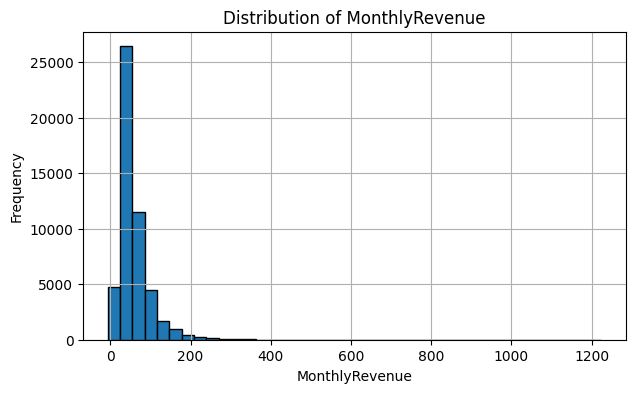

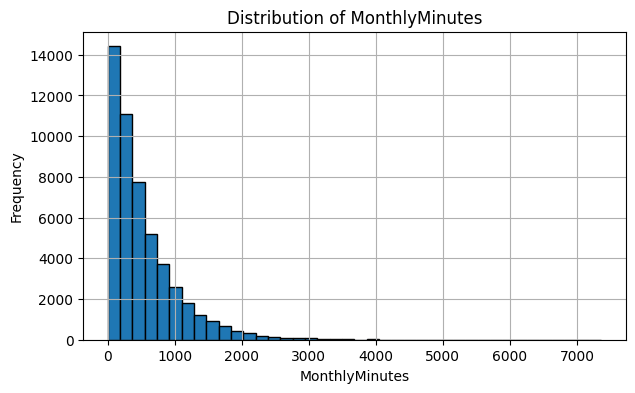

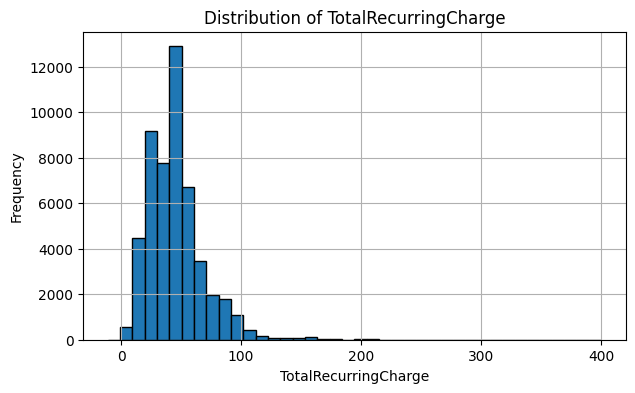

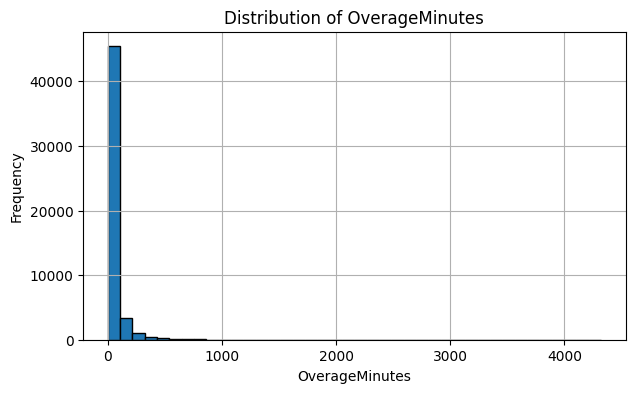

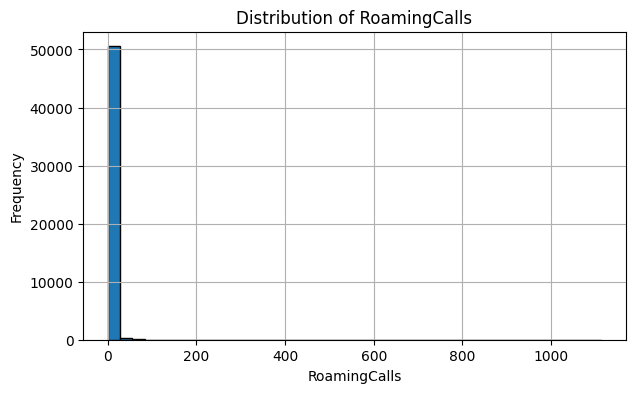

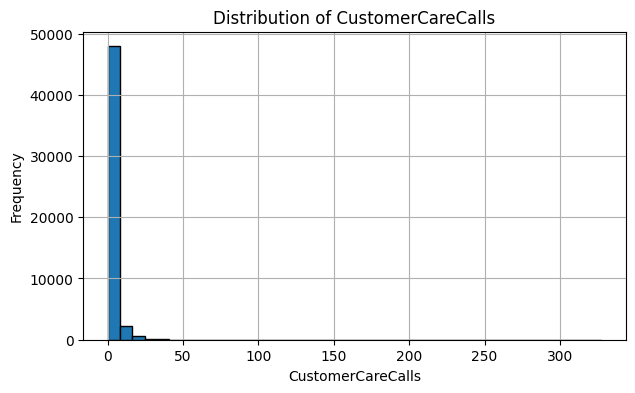

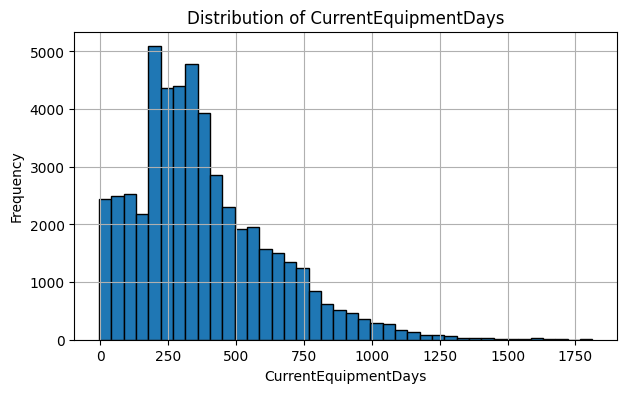

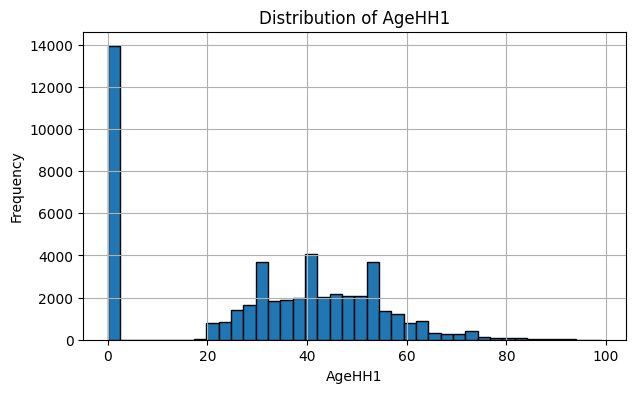

In [ ]:
# Representative raw numerical distributions
distribution_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "TotalRecurringCharge",
    "OverageMinutes",
    "RoamingCalls",
    "CustomerCareCalls",
    "CurrentEquipmentDays",
    "AgeHH1"
]

for col in distribution_features:
    plt.figure(figsize=(7, 4))
    train_raw[col].dropna().hist(
        bins=40,
        edgecolor="black"
    )
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

**Interpretation**

The numerical variables operate on substantially different ranges and several usage-related variables show asymmetric or long-tailed distributions. Large maximum values relative to medians are visible in variables such as call usage and roaming activity. These patterns are recorded as characteristics of the raw data and are investigated further through validity and outlier checks. No scaling or distributional transformation is performed during the audit.

### 2.9 Invalid, Impossible and Suspicious Values

This section checks for values that may be invalid, internally inconsistent or worthy of further investigation. A flagged value is **not automatically treated as an error** because its validity depends on the semantic meaning of the feature.

Negative values and selected logical relationships are inspected without modifying the data.

In [ ]:
# Identify numerical variables containing negative values
negative_value_summary = []

for col in numeric_cols:
    negative_count = (train_raw[col] < 0).sum()

    if negative_count > 0:
        negative_value_summary.append({
            "Feature": col,
            "Negative_Count": int(negative_count),
            "Minimum_Value": train_raw[col].min()
        })

negative_value_summary = pd.DataFrame(negative_value_summary)
display(negative_value_summary)

,Feature,Negative_Count,Minimum_Value
0,MonthlyRevenue,3,-6.17
1,TotalRecurringCharge,8,-11.00
2,PercChangeMinutes,26816,-3875.00
3,PercChangeRevenues,28408,-1107.70
4,CurrentEquipmentDays,76,-5.00


In [ ]:
# Selected logical consistency checks
logical_checks = pd.Series({
    "ActiveSubs > UniqueSubs":
        (train_raw["ActiveSubs"] > train_raw["UniqueSubs"]).sum(),

    "RetentionOffersAccepted > RetentionCalls":
        (
            train_raw["RetentionOffersAccepted"]
            > train_raw["RetentionCalls"]
        ).sum(),

    "HandsetModels > Handsets":
        (train_raw["HandsetModels"] > train_raw["Handsets"]).sum()
}, name="Violation_Count")

display(logical_checks.to_frame())

# Inspect zero values in household-age fields
print("AgeHH1 zero values:", (train_raw["AgeHH1"] == 0).sum())
print("AgeHH2 zero values:", (train_raw["AgeHH2"] == 0).sum())

,Violation_Count
ActiveSubs > UniqueSubs,0
RetentionOffersAccepted > RetentionCalls,0
HandsetModels > Handsets,0


AgeHH1 zero values: 13917
AgeHH2 zero values: 26087


**Interpretation**

Negative values are present in several variables. Negative percentage changes are mathematically plausible because they can represent decreases over time. Small numbers of negative values also occur in variables such as revenue, recurring charges and equipment days; these are treated as **suspicious/context-dependent observations rather than automatically invalid records**.

The selected logical consistency checks identify no cases where active subscriptions exceed unique subscriptions, accepted retention offers exceed retention calls, or handset models exceed handsets.

`AgeHH1` and `AgeHH2` also contain many zero values. The raw data alone does not establish whether these zeros represent genuine values, unavailable information, or a special coding convention. They are therefore documented without being replaced during the audit.

### 2.10 Outlier Investigation

Potential outliers are identified using the Interquartile Range (IQR) rule.

For each numerical variable:

- \(IQR = Q3 - Q1\)
- Lower fence = \(Q1 - 1.5 \times IQR\)
- Upper fence = \(Q3 + 1.5 \times IQR\)

Observations outside these fences are **flagged for investigation**, not automatically removed.

In [ ]:
# IQR-based outlier audit
outlier_summary = []

for col in numeric_cols:

    # CustomerID is an identifier, so an outlier concept is not meaningful here
    if col == "CustomerID":
        continue

    values = train_raw[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    flagged = (
        (values < lower_fence) |
        (values > upper_fence)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Fence": lower_fence,
        "Upper_Fence": upper_fence,
        "Flagged_Count": int(flagged),
        "Flagged_Percentage":
            round(flagged / len(values) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary).sort_values(
    "Flagged_Percentage",
    ascending=False
)

display(outlier_summary)

,Feature,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Flagged_Count,Flagged_Percentage
7,PercChangeRevenues,-7.10,1.600,8.700,-20.1500,14.6500,13221,26.09
5,RoamingCalls,0.00,0.300,0.300,-0.4500,0.7500,8835,17.36
20,CallWaitingCalls,0.00,1.300,1.300,-1.9500,3.2500,7448,14.59
6,PercChangeMinutes,-83.00,66.000,149.000,-306.5000,289.5000,6807,13.43
11,CustomerCareCalls,0.00,1.700,1.700,-2.5500,4.2500,6721,13.17
4,OverageMinutes,0.00,41.000,41.000,-61.5000,102.5000,5842,11.48
3,DirectorAssistedCalls,0.00,0.990,0.990,-1.4850,2.4750,5530,10.87
9,BlockedCalls,0.00,3.700,3.700,-5.5500,9.2500,5517,10.81
15,InboundCalls,0.00,9.300,9.300,-13.9500,23.2500,4973,9.74
12,ThreewayCalls,0.00,0.300,0.300,-0.4500,0.7500,4622,9.05


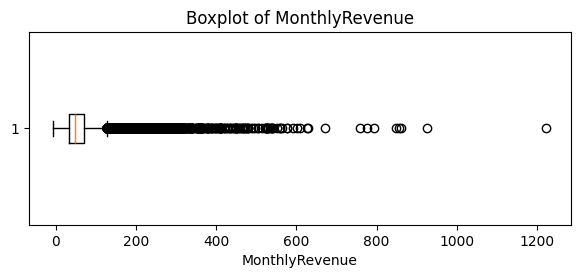

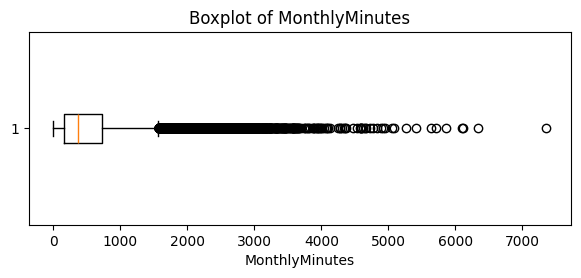

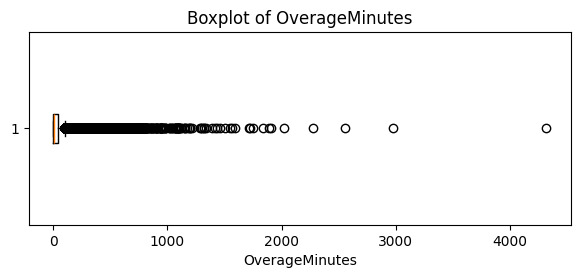

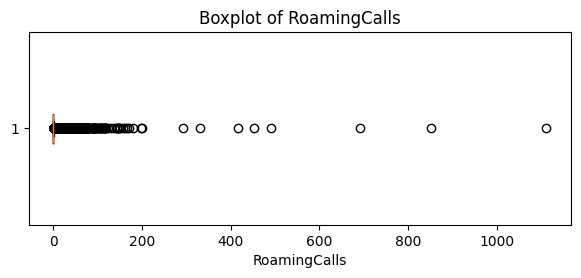

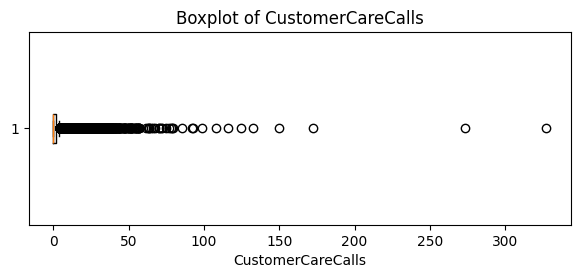

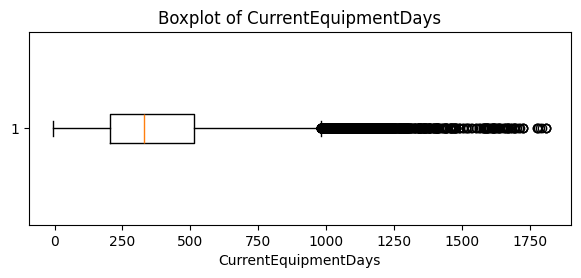

In [ ]:
# Selected boxplots for variables with potentially important extreme values
outlier_features = [
    "MonthlyRevenue",
    "MonthlyMinutes",
    "OverageMinutes",
    "RoamingCalls",
    "CustomerCareCalls",
    "CurrentEquipmentDays"
]

for col in outlier_features:
    plt.figure(figsize=(7, 2.5))
    plt.boxplot(
        train_raw[col].dropna(),
        vert=False
    )
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

**Interpretation**

The IQR analysis flags numerous observations in several usage-related variables. This is not sufficient evidence that those records are erroneous. Telecommunications usage can naturally include customers with activity levels far above the typical customer.

Accordingly, the audit records the existence of statistically unusual observations but does not remove, cap or transform them. Any later treatment must be justified using feature meaning and modelling evidence.

### 2.11 Target Distribution and Class Imbalance

The target distribution is inspected to determine whether the two churn classes are represented equally.

,Count,Percentage
Churn,,
No,36336,71.18
Yes,14711,28.82


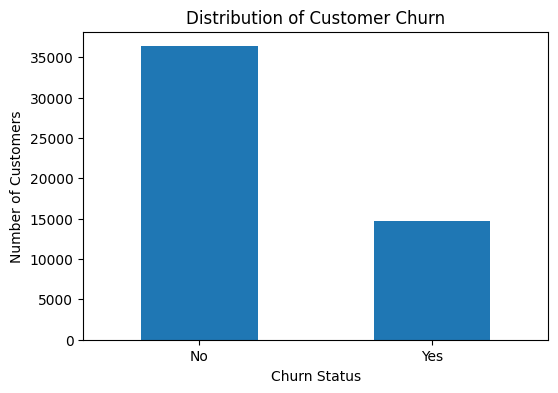

In [ ]:
# Target distribution
target_counts = train_raw["Churn"].value_counts()
target_percentages = (
    train_raw["Churn"].value_counts(normalize=True) * 100
).round(2)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(target_summary)

# Visualise target distribution
plt.figure(figsize=(6, 4))
target_counts.plot(kind="bar")
plt.title("Distribution of Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

**Interpretation**

The labelled dataset contains **36,336 non-churn customers (approximately 71.18%)** and **14,711 churn customers (approximately 28.82%)**. The target therefore exhibits moderate class imbalance.

### 2.12 Holdout Target Integrity

The target column in the separate holdout file is checked to confirm whether true churn outcomes are available.

In [ ]:
print(
    "Missing Churn labels in holdout:",
    holdout_raw["Churn"].isna().sum()
)

print(
    "Total holdout observations:",
    len(holdout_raw)
)

Missing Churn labels in holdout: 20000
Total holdout observations: 20000


**Interpretation**

All 20,000 `Churn` values in the provided holdout dataset are missing. Therefore, the holdout dataset cannot be used to calculate evaluation measures such as Accuracy, Precision, Recall, F1-score or ROC-AUC. It is retained as an unlabelled dataset for possible final inference after the modelling and evaluation workflow is completed.

### 2.13 Data Audit Summary

| Audit Area | Main Finding |
|---|---|
| Dataset size | 51,047 labelled observations and 58 variables |
| Holdout data | 20,000 observations with no observed `Churn` labels |
| Feature types | Mixture of numerical, binary categorical, nominal and ordered categorical information |
| Target | Binary `Churn` (`Yes` / `No`) |
| Exact duplicates | No complete duplicate rows identified |
| Identifier integrity | `CustomerID` is unique for every labelled observation |
| Actual missing values | Multiple variables contain null values |
| Explicit unknown values | Present in `Homeownership`, `HandsetPrice` and `MaritalStatus` |
| Categorical cardinality | `ServiceArea` contains hundreds of distinct categories |
| Representation issue | `HandsetPrice` contains price-like values together with `Unknown`, producing an object data type |
| Numerical distributions | Several usage-related variables are skewed and contain long tails |
| Suspicious values | Negative/context-dependent values occur in selected numerical fields and require interpretation |
| Internal consistency | Selected logical relationship checks show no violations |
| Potential outliers | IQR analysis flags numerous observations, especially among usage-related variables |
| Target balance | Approximately 71.18% non-churn and 28.82% churn |


## 3. Experimental Design and Data Partitioning

The objectives are to define the prediction task, assign clear roles to the variables, create a protected final-test partition and establish a reproducible development-only validation procedure. only a deterministic target-label mapping and separation of existing records into datasets are performed.

### 3.1 Experimental Design and Prediction Objective

The assignement addresses **supervised binary classification**: using information recorded about a wireless telecommunications customer, predict whether the customer's observed churn outcome is `Yes` or `No`. We designate **`Yes` (churn) as the positive class**, because identifying customers at risk of leaving is the intended use of the model.



---



**Intended prediction point.** In a practical retention setting, predictions should be made while the customer is still active and before the churn outcome is known. However, the Cell2Cell files do not provide an explicit observation timestamp, a churn-event timestamp or a verified forecast horizon. Consequently, this study evaluates prediction of the **recorded historical churn label** and cannot establish a prospective forecasting horizon from these files alone.



---



**Roles of the available datasets:**



*   **Labelled Cell2Cell data (`cell2celltrain.csv`, 51,047 rows)** : Source of model-development and final-test observations
*   **Development partition (80%)** : Model development
*   **Protected final-test partition (20%)** : Independent performance estimation
*   **Supplied unlabelled holdout (`cell2cellholdout.csv`, 20,000 rows)** : Optional inference dataset



---



**Feature availability caution.** Retention-related fields may describe interactions that occurred before or after a useful prediction point. Their availability is not established by the raw files. They will be explicitly reviewed before finalising modelling features; no claim of proven leakage is made at this stage.

### 3.2 Data Preparation Strategy (Planning Only)

The integrity audit identified several representation and data-quality characteristics. The following table records **provisional actions**, their reasons. These are not transformations applied to the data in this section. Approches will be implemented in relevent sections.

| Audit finding | Proposed approach | Reason |
|---|---|---|
| Actual missing values in numerical and categorical fields | Assess suitable numerical/categorical imputation and possible missingness indicators | Models generally require explicit handling of missing predictors |
| `HandsetPrice` contains numeric-like strings and `Unknown` | Investigate numeric parsing, the meaning of `Unknown`, and a suitable missing-value representation | Storage type does not match the meaning of known prices |
| `Homeownership` and `MaritalStatus` contain explicit `Unknown` | Decide whether to retain `Unknown` as a category or treat it as missing, based on meaning | An explicit response is not automatically equivalent to a null value |
| Nominal, binary and potentially ordered categorical variables | Choose encoding appropriate to each semantic type; verify uncertain ordinal mappings | Arbitrary integer codes can introduce false ordering |
| High-cardinality `ServiceArea` | Investigate encoding complexity and handling of unseen categories | Hundreds of distinct codes may expand the feature space |
| Negative/context-dependent values and zero-coded ages | Review plausibility and coding conventions before changing anything | The raw file alone does not prove these are errors |
| Skewed distributions and IQR-flagged observations | Compare retaining, transforming or robustly handling selected features if justified | IQR flags are not automatic evidence of invalid records |
| Different numerical scales | Use model-appropriate scaling (especially for Logistic Regression) | Scale-sensitive optimisation can be affected by feature magnitude |
| Unique `CustomerID` | Keep separately for integrity checks; do not use as a predictor | An identifier is not a meaningful behavioural input |
| Churn class imbalance (~28.82% positive) | Preserve class proportions in splitting; later compare justified imbalance-aware methods | Prevent misleading validation and minority-class performance conclusions |
| Retention-related fields with uncertain timing | Review prediction-time availability; define a defensible feature policy before training | Avoid using information unavailable at prediction time |

### 3.3 Feature and Target Definition

In [ ]:
# Define the roles of the original columns without modifying train_raw.
TARGET_COL = "Churn"
ID_COL = "CustomerID"

assert TARGET_COL in train_raw.columns
assert ID_COL in train_raw.columns
assert train_raw.columns.is_unique, "Source contains duplicate column names."

candidate_feature_cols = [
    col for col in train_raw.columns
    if col not in {TARGET_COL, ID_COL}
]

# X: all colummns except churn and customerID
X = train_raw.loc[:, candidate_feature_cols].copy()

# Original churn label, stored as yes or no
y_raw = train_raw[TARGET_COL].copy()

# Record identifier
customer_ids = train_raw[ID_COL].copy()

feature_role_summary = pd.DataFrame([
    {"Role": "Candidate predictors (X)", "Number_of_columns": X.shape[1],
     "Description": "All original columns except Churn and CustomerID"},
    {"Role": "Target (y_raw)", "Number_of_columns": 1,
     "Description": "Original observed Churn label (Yes / No)"},
    {"Role": "Identifier (customer_ids)", "Number_of_columns": 1,
     "Description": "CustomerID; retained for verification, not prediction"},
])

display(feature_role_summary)
print("Candidate predictor matrix:", X.shape)
print("Raw target vector:", y_raw.shape)
print("Identifier vector:", customer_ids.shape)

assert X.shape[1] == train_raw.shape[1] - 2
assert TARGET_COL not in X.columns and ID_COL not in X.columns
assert X.index.equals(y_raw.index) and X.index.equals(customer_ids.index)

,Role,Number_of_columns,Description
0,Candidate predictors (X),56,All original columns except Churn and CustomerID
1,Target (y_raw),1,Original observed Churn label (Yes / No)
2,Identifier (customer_ids),1,"CustomerID; retained for verification, not pre..."


Candidate predictor matrix: (51047, 56)
Raw target vector: (51047,)
Identifier vector: (51047,)


**Prediction-time feature review.** `RetentionCalls`, `RetentionOffersAccepted` and `MadeCallToRetentionTeam` are included provisionally in `X` but flagged below because their timing relative to churn is not established. They are **not automatically classified as leakage**. A conservative feature policy or a development-only sensitivity comparison can be established before model training, without consulting the final-test results.

In [ ]:
# Record potentially time-sensitive variables for review before modelling.
retention_features_to_review = [
    "RetentionCalls",
    "RetentionOffersAccepted",
    "MadeCallToRetentionTeam",
]

assert set(retention_features_to_review).issubset(X.columns)

feature_availability_review = pd.DataFrame({
    "Feature": retention_features_to_review,
    "Current_status": ["Timing not verified"] * len(retention_features_to_review),
    "Required_check": [
        "Was the call count known before the intended churn prediction?",
        "Were accepted offers recorded before the intended prediction?",
        "Was contact with the retention team known before prediction?",
    ],
    "Action_now": ["Flag for pre-modelling review; do not remove yet"] * 3,
})

display(feature_availability_review)

,Feature,Current_status,Required_check,Action_now
0,RetentionCalls,Timing not verified,Was the call count known before the intended c...,Flag for pre-modelling review; do not remove yet
1,RetentionOffersAccepted,Timing not verified,Were accepted offers recorded before the inten...,Flag for pre-modelling review; do not remove yet
2,MadeCallToRetentionTeam,Timing not verified,Was contact with the retention team known befo...,Flag for pre-modelling review; do not remove yet


### 3.4 Target Representation and Validation

For binary classification, encode the target deterministically as **`No → 0`** and **`Yes → 1`**. The positive label `1` will represent customer churn in later evaluation metrics.

Before mapping, verify that the labelled dataset contains **no missing or unexpected churn labels**. Mapping is performed on the separate target vector; the original text-valued `train_raw["Churn"]` is not overwritten.

In [ ]:
# Validate the observed labels before encoding.
LABEL_MAP = {"No": 0, "Yes": 1}
POSITIVE_CLASS = 1

assert y_raw.notna().all(), "Labelled data contains missing Churn values."

unexpected_labels = set(y_raw.unique()) - set(LABEL_MAP)
assert not unexpected_labels, f"Unexpected Churn values: {unexpected_labels}"
assert set(y_raw.unique()) == set(LABEL_MAP), "Expected both churn classes."

# Deterministic target encoding; no fitted transformation or data leakage.
y = y_raw.map(LABEL_MAP).astype("int8")

assert y.notna().all()
assert set(y.unique()) == {0, 1}
assert y.index.equals(X.index)

label_summary = pd.DataFrame({
    "Original_label": ["No", "Yes"],
    "Encoded_label": [0, 1],
    "Count": [int((y == 0).sum()), int((y == 1).sum())],
    "Percentage": [round((y == 0).mean() * 100, 2),
                   round((y == 1).mean() * 100, 2)],
})

display(label_summary)
print("Target validation: PASSED")
print("Original raw target unchanged:", train_raw[TARGET_COL].equals(y_raw))

,Original_label,Encoded_label,Count,Percentage
0,No,0,36336,71.18
1,Yes,1,14711,28.82


Target validation: PASSED
Original raw target unchanged: True


### 3.5 Data Partitioning Strategy

We use a **single stratified random 80% development / 20% final-test split**, with `random_state=42` for reproducibility. The development partition will be used for EDA, model development, cross-validation and all model-selection decisions. The final-test partition will remain isolated until the selected workflow is fixed.

**Why stratification?** Churn occurs in approximately 28.82% of labelled observations. Stratification keeps the proportion of churn/non-churn customers approximately consistent across both partitions.

**Why a random customer-level split?** The audit confirmed one unique `CustomerID` per labelled record and no exact duplicate rows. The files do not expose a reliable observation-date or churn-event-date column from which to construct a chronological split. A stratified random split is therefore a reasonable **internal benchmark** for these records. It does **not** establish performance on future customer cohorts or rule out all unobserved group/time effects. If reliable timestamps or repeated-customer groups become available, a time-aware or group-aware evaluation would be preferable for those settings.

**Important distinction:** the separately supplied 20,000-row unlabelled holdout is **not** the final test set, because its churn outcomes are unavailable.

### 3.6 Development and Final-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.20

assert train_raw.index.is_unique, "Row index must uniquely identify each observation."
assert customer_ids.notna().all(), "CustomerID contains missing values."
assert customer_ids.is_unique, "CustomerID must be unique for this split strategy."

# Split row indices so features, target and customer IDs remain aligned.
dev_idx, test_idx = train_test_split(
    train_raw.index.to_numpy(),
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

# Separate copies of the raw candidate predictors and their labels.
X_dev = X.loc[dev_idx].copy()
X_test = X.loc[test_idx].copy()
y_dev = y.loc[dev_idx].copy()
y_test = y.loc[test_idx].copy()

# IDs are kept for integrity verification, not for model fitting.
customer_ids_dev = customer_ids.loc[dev_idx].copy()
customer_ids_test = customer_ids.loc[test_idx].copy()

partition_summary = pd.DataFrame([
    {"Partition": "Development", "Observations": len(X_dev),
     "Predictor_columns": X_dev.shape[1],
     "Percentage_of_labelled_data": round(100 * len(X_dev) / len(X), 2)},
    {"Partition": "Protected final test", "Observations": len(X_test),
     "Predictor_columns": X_test.shape[1],
     "Percentage_of_labelled_data": round(100 * len(X_test) / len(X), 2)},
])

display(partition_summary)
print("X_dev:", X_dev.shape, "| y_dev:", y_dev.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)
print("Unlabelled holdout kept separate:", holdout_raw.shape)

,Partition,Observations,Predictor_columns,Percentage_of_labelled_data
0,Development,40837,56,80.0
1,Protected final test,10210,56,20.0


X_dev: (40837, 56) | y_dev: (40837,)
X_test: (10210, 56) | y_test: (10210,)
Unlabelled holdout kept separate: (20000, 58)


**Interpretation.** The labelled dataset has been divided into **40,837 development customers** and **10,210 protected final-test customers**. Each feature matrix retains the **56 initial candidate predictors** in their original, unprocessed representation.

### 3.7 Split Integrity Verification

The following checks use the protected test set **only for partition integrity and class-balance verification**, not to choose features, preprocessing methods, model configurations or thresholds.

In [ ]:
# Verify the partition structure without fitting or tuning any model.
checks = {
    "All labelled observations accounted for":
        len(X_dev) + len(X_test) == len(train_raw),
    "No shared row indices":
        set(X_dev.index).isdisjoint(set(X_test.index)),
    "No shared customer IDs":
        set(customer_ids_dev).isdisjoint(set(customer_ids_test)),
    "Customer IDs unique within both partitions":
        customer_ids_dev.is_unique and customer_ids_test.is_unique,
    "Development features, target and IDs aligned":
        X_dev.index.equals(y_dev.index) and X_dev.index.equals(customer_ids_dev.index),
    "Final-test features, target and IDs aligned":
        X_test.index.equals(y_test.index) and X_test.index.equals(customer_ids_test.index),
    "Identical predictor columns and order":
        X_dev.columns.equals(X_test.columns),
    "No target or identifier in predictor matrices":
        all(col not in X_dev.columns for col in [TARGET_COL, ID_COL])
        and all(col not in X_test.columns for col in [TARGET_COL, ID_COL]),
    "No missing or unexpected encoded target labels":
        y_dev.notna().all() and y_test.notna().all()
        and set(y_dev.unique()) == {0, 1}
        and set(y_test.unique()) == {0, 1},
    "Raw labelled target remains unchanged":
        train_raw[TARGET_COL].equals(y_raw),
    "Supplied holdout remains unlabelled":
        holdout_raw[TARGET_COL].isna().all(),
}

verification_table = pd.DataFrame({
    "Integrity_check": list(checks),
    "Status": ["PASS" if result else "FAIL" for result in checks.values()],
})

display(verification_table)
assert all(checks.values()), "At least one partition-integrity check failed."
print("All split-integrity checks passed.")

,Integrity_check,Status
0,All labelled observations accounted for,PASS
1,No shared row indices,PASS
2,No shared customer IDs,PASS
3,Customer IDs unique within both partitions,PASS
4,"Development features, target and IDs aligned",PASS
5,"Final-test features, target and IDs aligned",PASS
6,Identical predictor columns and order,PASS
7,No target or identifier in predictor matrices,PASS
8,No missing or unexpected encoded target labels,PASS
9,Raw labelled target remains unchanged,PASS


All split-integrity checks passed.


In [ ]:
# Compare target distributions for structural verification only.
distribution_records = []

for partition_name, labels in [
    ("All labelled data", y),
    ("Development", y_dev),
    ("Protected final test", y_test),
]:
    distribution_records.append({
        "Partition": partition_name,
        "Total": len(labels),
        "No_churn_0": int((labels == 0).sum()),
        "Churn_1": int((labels == 1).sum()),
        "Churn_percentage": round(100 * (labels == 1).mean(), 2),
    })

split_class_distribution = pd.DataFrame(distribution_records)
display(split_class_distribution)

# Stratification should maintain very similar positive-class rates.
assert abs(y_dev.mean() - y.mean()) < 0.01
assert abs(y_test.mean() - y.mean()) < 0.01
print("Class-proportion verification: PASSED")

,Partition,Total,No_churn_0,Churn_1,Churn_percentage
0,All labelled data,51047,36336,14711,28.82
1,Development,40837,29068,11769,28.82
2,Protected final test,10210,7268,2942,28.81


Class-proportion verification: PASSED


**Interpretation.** All integrity checks pass: the two partitions are disjoint, every labelled customer is assigned to exactly one partition, identifiers are excluded from model inputs, and labels remain aligned with their respective feature rows. The development set contains **29,068 non-churn and 11,769 churn** observations; the protected test contains **7,268 non-churn and 2,942 churn** observations. Both retain a churn rate of approximately **28.82%**.

These checks establish **structural correctness**, not an estimate of predictive performance.

### 3.8 Cross-Validation, Evaluation Criteria and Leakage Prevention

#### Validation protocol

Within the **development set only**, use **five-fold stratified cross-validation** (`StratifiedKFold`, `shuffle=True`, `random_state=42`). In each fold, approximately four-fifths of the development observations form a training fold and the remainder form a validation fold. Each development observation serves as validation data exactly once across the five folds. The protected final test set is **never included in these folds**.

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import make_scorer, matthews_corrcoef

N_CV_SPLITS = 5
cv = StratifiedKFold(
    n_splits=N_CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Average Precision summarizes precision-recall performance across thresholds.
PRIMARY_SCORING = "average_precision"
CV_SCORING = {
    "average_precision": "average_precision",  # primary model-selection metric
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
    "accuracy": "accuracy",
    "mcc": make_scorer(matthews_corrcoef),
}

# Verify fold structure without fitting any preprocessing or classifier.
fold_rows = []
validation_appearances = np.zeros(len(X_dev), dtype=int)

for fold_number, (train_positions, valid_positions) in enumerate(
    cv.split(X_dev, y_dev), start=1
):
    assert set(train_positions).isdisjoint(set(valid_positions))
    validation_appearances[valid_positions] += 1

    fold_rows.append({
        "Fold": fold_number,
        "Training_rows": len(train_positions),
        "Validation_rows": len(valid_positions),
        "Training_churn_pct": round(100 * y_dev.iloc[train_positions].mean(), 2),
        "Validation_churn_pct": round(100 * y_dev.iloc[valid_positions].mean(), 2),
    })

cv_fold_summary = pd.DataFrame(fold_rows)
assert len(cv_fold_summary) == N_CV_SPLITS
assert (validation_appearances == 1).all(), (
    "Every development observation should appear in exactly one validation fold."
)

display(cv_fold_summary)
print("Cross-validation configuration: 5-fold stratified, shuffled, seed =", RANDOM_STATE)
print("Primary future model-selection metric:", PRIMARY_SCORING)
print("Additional metrics:", ", ".join(k for k in CV_SCORING if k != PRIMARY_SCORING))
print("Cross-validation fold integrity: PASSED")

,Fold,Training_rows,Validation_rows,Training_churn_pct,Validation_churn_pct
0,1,32669,8168,28.82,28.82
1,2,32669,8168,28.82,28.82
2,3,32670,8167,28.82,28.81
3,4,32670,8167,28.82,28.82
4,5,32670,8167,28.82,28.82


Cross-validation configuration: 5-fold stratified, shuffled, seed = 42
Primary future model-selection metric: average_precision
Additional metrics: roc_auc, f1, recall, precision, accuracy, mcc
Cross-validation fold integrity: PASSED


**Interpretation.** Each of the five validation folds contains approximately **8,167–8,168** development observations, with a churn rate close to the development-set prevalence. Every development observation is assigned to exactly one validation fold. The final-test set is excluded from this procedure.

All data-dependent preprocessing operations, including imputation, scaling, encoding, resampling and feature selection, will be fitted using the training portion of each cross-validation fold. The fitted transformations will then be applied to the corresponding validation fold. The protected final-test set will not be used to select preprocessing methods, features, models, hyperparameters or decision thresholds

#### Leakage-prevention rules

1. **Split first.** No data-dependent imputation, scaling, categorical-vocabulary learning, outlier-bound fitting, resampling or feature screening is performed on the complete labelled dataset before splitting.
2. **Fit within each training fold.** Future `Pipeline`/`ColumnTransformer` operations learn statistics and encodings from the fold's training observations, then transform the corresponding validation observations.
3. **Use development data for decisions.** Feature availability decisions, preprocessing alternatives, imbalance treatments, model/hyperparameter comparisons and threshold selection are based on domain reasoning and development/CV evidence only.
4. **Compare models fairly.** Logistic Regression and Random Forest will use the same development partition, stratified CV configuration and reporting metrics; model-specific preprocessing may differ when justified.
5. **Protect the final test.** After the model configuration and threshold are fixed, refit the chosen pipeline on the full development partition and evaluate once on `X_test`/`y_test`. The unlabelled supplied holdout cannot provide evaluation metrics.

### 3.9 Experimental Design Summary

| Design element | Finalised decision |
|---|---|
| Learning task | Supervised binary classification of the observed Cell2Cell `Churn` outcome |
| Positive class | `Yes` encoded as `1` (`No` encoded as `0`) |
| Labelled data | 51,047 customers |
| Candidate inputs | 56 raw candidate predictors; `CustomerID` excluded and retained separately |
| Prediction-time caveat | No verified observation/churn timestamps; retention-related fields flagged for pre-modelling availability review |
| Partitioning | 80% development (40,837) / 20% protected final test (10,210) |
| Split method | Stratified random split, `random_state=42` |
| Development validation | Five-fold shuffled `StratifiedKFold`, `random_state=42` |
| Primary future model-selection metric | Average Precision (`average_precision`) |
| Supporting evaluation | ROC-AUC, precision, recall, F1, MCC, accuracy and confusion matrix |
| Supplied holdout | 20,000 customers without observed churn labels; optional inference only |
| Leakage safeguards | Training-fold-only fitted transformations; development-only selection; one untouched final-test evaluation |

The experimental protocol, data roles, target encoding, partitioning and validation configuration are established and verified. No feature values have been cleaned, imputed, scaled, encoded or removed, and no model has been fitted. The **original raw datasets remain unchanged**.

## 4. Development-Only Exploratory Data Analysis (EDA)

This section investigates **patterns associated with churn within the development partition**. It is exploratory evidence for later preprocessing and modelling decisions, not a source of final model-performance claims.

**Scope:** all descriptive statistics, plots and temporary groupings use `X_dev` and `y_dev`. The protected `X_test`/`y_test` and the supplied unlabelled holdout are not used. No imputation, scaling, encoding, row removal, resampling, feature selection or model fitting is performed.

### 4.1 EDA Objectives, Safeguards and Reusable Baseline

A **separate analysis DataFrame** containing development predictors and their observed churn labels is created. This does **not** alter the modelling matrices. The helper below adds a dashed line to all subsequent **churn-rate** charts. The line represents the *same* development prevalence, rather than a new baseline computed separately for each subgroup.

A positive difference means the observed subgroup churn rate is **above** the development baseline; it does **not** establish causation, statistical significance or predictive utility.

In [ ]:
# Work exclusively with the development partition; preserve the modelling inputs.
assert X_dev.index.equals(y_dev.index), "Development features and labels are misaligned."
assert "Churn" not in X_dev.columns and "CustomerID" not in X_dev.columns

eda_dev = X_dev.copy()
eda_dev["Churn"] = y_dev  # Pandas aligns the labels by original row index.

DEV_CHURN_RATE = float(y_dev.mean())
DEV_CHURN_PCT = 100 * DEV_CHURN_RATE


def add_churn_baseline(ax, orientation="horizontal"):
    """Add the SAME development churn rate to a percentage-scale chart."""
    label = f"Development baseline: {DEV_CHURN_PCT:.2f}%"
    if orientation == "horizontal":  # horizontal line for vertical bars
        ax.axhline(DEV_CHURN_PCT, color="black", linestyle="--", linewidth=1.4, label=label)
    elif orientation == "vertical":  # vertical line for horizontal bars
        ax.axvline(DEV_CHURN_PCT, color="black", linestyle="--", linewidth=1.4, label=label)
    else:
        raise ValueError("orientation must be 'horizontal' or 'vertical'")

assert eda_dev.shape == (len(X_dev), X_dev.shape[1] + 1)
assert eda_dev["Churn"].equals(y_dev)
print(f"Development EDA: {len(eda_dev):,} customers, {X_dev.shape[1]} predictors")
print(f"Single reference churn rate: {DEV_CHURN_PCT:.2f}%")

Development EDA: 40,837 customers, 56 predictors
Single reference churn rate: 28.82%


**Interpretation.** All analyses below refer to the **40,837 development customers**, with a reference churn rate of **28.82%**. Subgroup differences will be expressed in **percentage points (pp)** relative to this baseline. The separate `eda_dev` object is used for inspection only; the original development predictors and labels remain available unchanged for the leakage-safe pipelines in later sections.

### 4.2 Development Dataset Overview and Feature Types

This is a short development-only overview. Distinguish the types pandas currently stores, which may differ from the **semantic types** that future preprocessing must use (for example, `HandsetPrice` is stored as text even though known values represent prices).

In [ ]:
eda_numeric_columns = X_dev.select_dtypes(include=np.number).columns.tolist()
eda_object_columns = X_dev.select_dtypes(exclude=np.number).columns.tolist()

eda_overview = pd.DataFrame([
    {"Property": "Development observations", "Value": len(X_dev)},
    {"Property": "Candidate predictor columns", "Value": X_dev.shape[1]},
    {"Property": "Numerically stored predictors", "Value": len(eda_numeric_columns)},
    {"Property": "Non-numerically stored predictors", "Value": len(eda_object_columns)},
    {"Property": "Predictors with actual nulls", "Value": int(X_dev.isna().any().sum())},
    {"Property": "Target positive class", "Value": "Churn = 1 (Yes)"},
    {"Property": "Development churn prevalence", "Value": f"{DEV_CHURN_PCT:.2f}%"},
])
display(eda_overview)
print("Examples of numerical predictors:", ", ".join(eda_numeric_columns[:9]))
print("Examples of stored text predictors:", ", ".join(eda_object_columns[:9]))

,Property,Value
0,Development observations,40837
1,Candidate predictor columns,56
2,Numerically stored predictors,34
3,Non-numerically stored predictors,22
4,Predictors with actual nulls,14
5,Target positive class,Churn = 1 (Yes)
6,Development churn prevalence,28.82%


Examples of numerical predictors: MonthlyRevenue, MonthlyMinutes, TotalRecurringCharge, DirectorAssistedCalls, OverageMinutes, RoamingCalls, PercChangeMinutes, PercChangeRevenues, DroppedCalls
Examples of stored text predictors: ServiceArea, ChildrenInHH, HandsetRefurbished, HandsetWebCapable, TruckOwner, RVOwner, Homeownership, BuysViaMailOrder, RespondsToMailOffers


**Interpretation.** The development predictors contain **34 numerically stored** and **22 non-numerically stored** columns. Storage type alone does not decide how a feature should be encoded: some numeric codes can represent ordered groups, and `HandsetPrice` contains a textual missing-value representation.

### 4.3 Development Churn Distribution and Reference Rate

The development-set churn prevalence is our common reference for interpreting all subsequent subgroup churn-rate charts. We also calculate the **illustrative majority-class accuracy**: the accuracy a trivial rule would obtain by always predicting the more frequent class. This is not a trained `DummyClassifier` result; the actual baseline model is reserved for the modelling stage.

,Outcome,Customers,Percentage
0,No churn (0),29068,71.18
1,Churn (1),11769,28.82


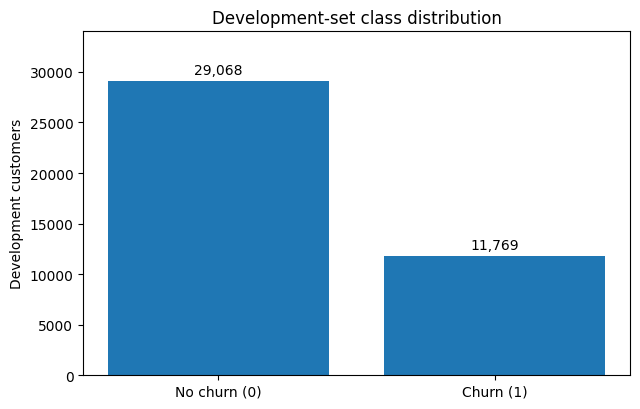

Reference churn rate: 28.82%
Illustrative always-No accuracy (not a fitted model): 71.18%


In [ ]:
eda_target_counts = y_dev.value_counts().reindex([0, 1], fill_value=0)
eda_target_summary = pd.DataFrame({
    "Outcome": ["No churn (0)", "Churn (1)"],
    "Customers": eda_target_counts.to_numpy(),
    "Percentage": (100 * eda_target_counts / len(y_dev)).round(2).to_numpy(),
})
display(eda_target_summary)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(eda_target_summary["Outcome"], eda_target_summary["Customers"])
for bar, count in zip(bars, eda_target_summary["Customers"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 450,
            f"{count:,}", ha="center", va="bottom")
ax.set_ylim(0, eda_target_summary["Customers"].max() * 1.17)
ax.set_ylabel("Development customers")
ax.set_title("Development-set class distribution")
plt.tight_layout()
plt.show()

majority_accuracy = 100 * eda_target_counts.max() / len(y_dev)
print(f"Reference churn rate: {DEV_CHURN_PCT:.2f}%")
print(f"Illustrative always-No accuracy (not a fitted model): {majority_accuracy:.2f}%")

**Interpretation.** There are **29,068 non-churners (71.18%)** and **11,769 churners (28.82%)** in the development set. A classifier that always predicts `No` could achieve **71.18% accuracy** while identifying **zero churners**. Therefore, accuracy alone is not sufficient. All subsequent subgroup rates are compared with the **28.82% reference**, while future models will be compared using the predefined Average Precision and supporting metrics from Section 3.8.

### 4.4 Numerical Feature Distributions — Shape, Skewness, Zeros and Tails

Before comparing classes, we examine **how selected numerical predictors are distributed among all development customers**. This helps identify zero-heavy variables, right-skewed usage measures, long tails and potential transformation requirements.

The summary statistics below use **all available development values**. For readable histograms only, the **display window** is restricted to the **1st–99th percentiles** of each variable. This does **not** trim, remove, cap or otherwise modify any observation. Counts of missing and zero values are reported separately. Extreme values remain present in `X_dev`.

In [ ]:
eda_distribution_features = [
    "MonthlyRevenue", "MonthlyMinutes", "MonthsInService", "CustomerCareCalls",
    "DroppedCalls", "OverageMinutes", "CurrentEquipmentDays", "RoamingCalls",
]
assert set(eda_distribution_features).issubset(X_dev.columns)

numeric_distribution_rows = []
for feature in eda_distribution_features:
    s = pd.to_numeric(X_dev[feature], errors="coerce")
    nonmissing = s.dropna()
    numeric_distribution_rows.append({
        "Feature": feature,
        "Missing_%": round(100 * s.isna().mean(), 2),
        "Zero_%_of_all_rows": round(100 * s.eq(0).mean(), 2),
        "Mean": round(nonmissing.mean(), 2),
        "Median": round(nonmissing.median(), 2),
        "P95": round(nonmissing.quantile(0.95), 2),
        "P99": round(nonmissing.quantile(0.99), 2),
        "Maximum": round(nonmissing.max(), 2),
        "Skewness": round(nonmissing.skew(), 2),
    })
numeric_distribution_summary = pd.DataFrame(numeric_distribution_rows)
display(numeric_distribution_summary)

,Feature,Missing_%,Zero_%_of_all_rows,Mean,Median,P95,P99,Maximum,Skewness
0,MonthlyRevenue,0.29,0.01,58.99,48.47,136.31,228.33,1223.38,4.31
1,MonthlyMinutes,0.29,1.40,525.24,367.00,1569.20,2450.00,7359.00,2.19
2,MonthsInService,0.00,0.00,18.78,16.00,37.00,49.00,61.00,1.06
3,CustomerCareCalls,0.00,54.89,1.87,0.00,9.30,21.30,327.30,12.88
4,DroppedCalls,0.00,15.05,6.01,3.00,22.00,42.30,221.70,4.39
5,OverageMinutes,0.29,45.59,40.31,3.00,191.00,434.00,4321.00,8.36
6,CurrentEquipmentDays,0.00,0.04,380.44,329.00,866.00,1141.65,1812.00,1.08
7,RoamingCalls,0.29,68.66,1.24,0.00,5.00,21.58,1112.40,58.99


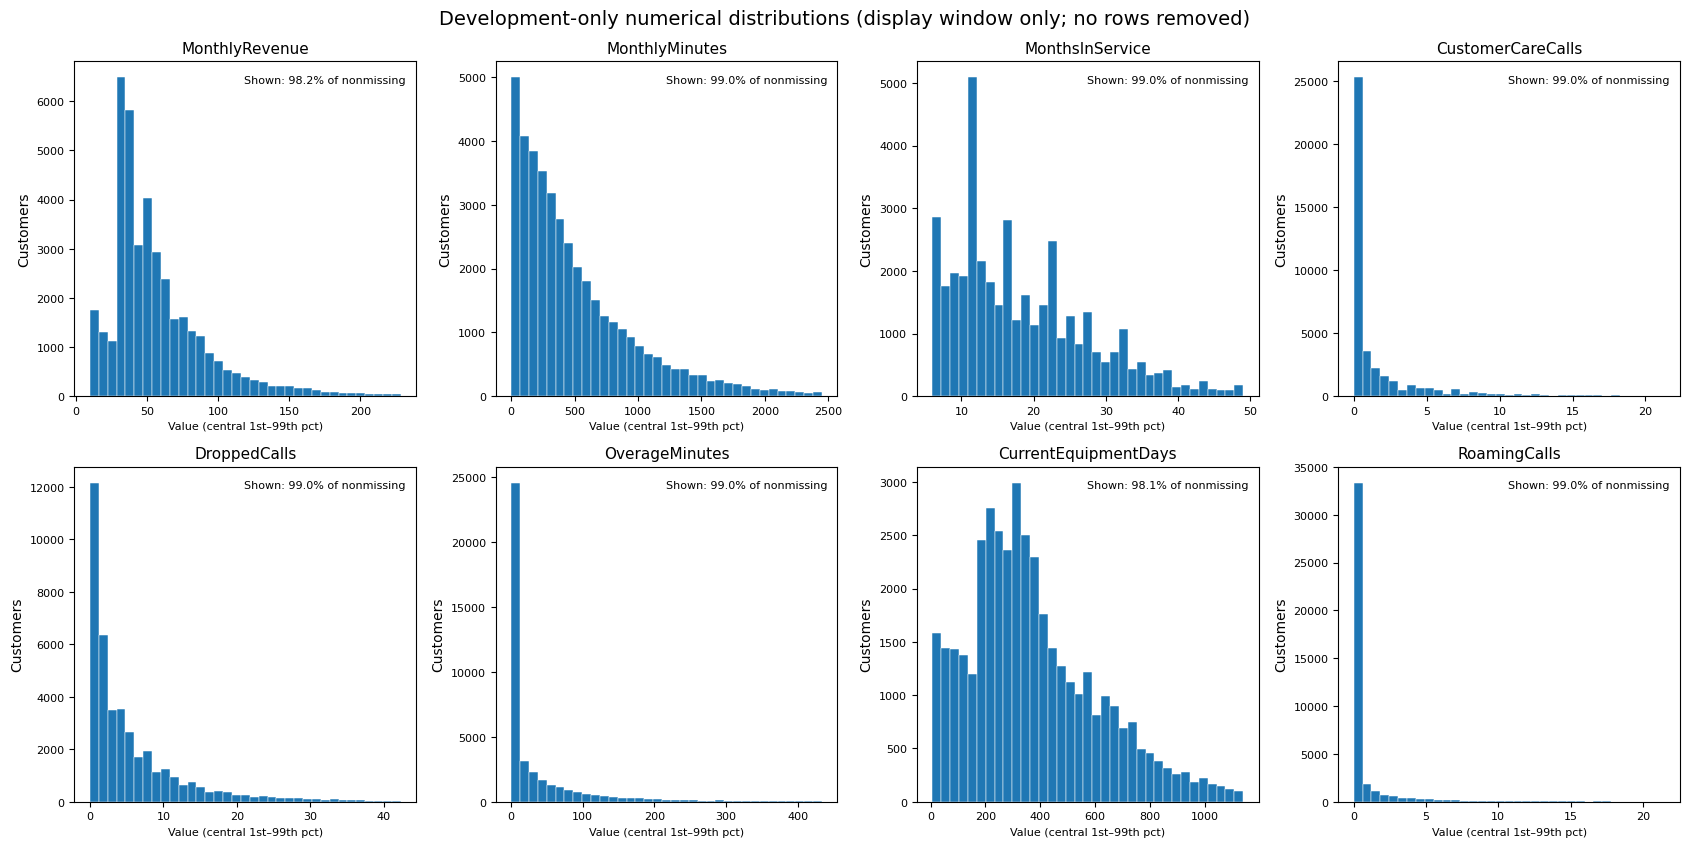

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8.6))
for ax, feature in zip(axes.flat, eda_distribution_features):
    values = pd.to_numeric(X_dev[feature], errors="coerce").dropna()
    lower, upper = values.quantile([0.01, 0.99])
    if lower >= upper:
        lower, upper = values.min(), values.max()
    visible = values.between(lower, upper)
    ax.hist(values[visible], bins=35, edgecolor="white", linewidth=0.35)
    ax.set_title(feature, fontsize=11)
    ax.set_ylabel("Customers")
    ax.set_xlabel("Value (central 1st–99th pct)", fontsize=8)
    ax.tick_params(axis="both", labelsize=8)
    ax.text(0.97, 0.96, f"Shown: {visible.mean()*100:.1f}% of nonmissing",
            transform=ax.transAxes, ha="right", va="top", fontsize=8,
            bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"})
fig.suptitle("Development-only numerical distributions (display window only; no rows removed)", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation.** Usage and billing variables have noticeably different scales and several distributions are strongly **right-skewed**. For example, `RoamingCalls` has a long positive tail and is **zero for approximately 68.7%** of development customers; `CustomerCareCalls` is **zero for approximately 54.9%**, and `OverageMinutes` for **45.6%**. `MonthlyRevenue` and `MonthlyMinutes` also show substantial upper tails. `MonthsInService` and `CurrentEquipmentDays` have different ranges and shapes.

The displayed histograms intentionally focus on the central 98% of nonmissing values to make typical patterns visible; the distribution table retains the **full observed maxima**. **No value is treated as erroneous solely because it is extreme.**.

### 4.5 Numerical Predictors Compared Between Churn Classes

Compare selected numerical features between `Churn=0` and `Churn=1`. The boxplots suppress outlier markers for readability only (`showfliers=False`); all records remain in the data and contribute to the summaries. These are descriptive associations, not causal effects or feature-selection decisions.

In [ ]:
class_compare_features = [
    "MonthlyRevenue", "MonthlyMinutes", "MonthsInService", "CustomerCareCalls",
    "DroppedCalls", "OverageMinutes", "CurrentEquipmentDays",
]
class_comparison_rows = []
for feature in class_compare_features:
    s = pd.to_numeric(X_dev[feature], errors="coerce")
    no_values = s[y_dev == 0].dropna()
    yes_values = s[y_dev == 1].dropna()
    class_comparison_rows.append({
        "Feature": feature,
        "No_churn_N": len(no_values),
        "Churn_N": len(yes_values),
        "No_churn_median": round(no_values.median(), 2),
        "Churn_median": round(yes_values.median(), 2),
        "Median_difference_Churn_minus_No": round(yes_values.median() - no_values.median(), 2),
        "No_churn_mean": round(no_values.mean(), 2),
        "Churn_mean": round(yes_values.mean(), 2),
    })
numerical_churn_comparison = pd.DataFrame(class_comparison_rows)
display(numerical_churn_comparison)

,Feature,No_churn_N,Churn_N,No_churn_median,Churn_median,Median_difference_Churn_minus_No,No_churn_mean,Churn_mean
0,MonthlyRevenue,29003,11714,48.81,47.51,-1.3,59.29,58.26
1,MonthlyMinutes,29003,11714,381.00,331.00,-50.0,541.64,484.65
2,MonthsInService,29068,11769,16.00,17.00,1.0,18.64,19.14
3,CustomerCareCalls,29068,11769,0.00,0.00,0.0,1.98,1.58
4,DroppedCalls,29068,11769,3.00,3.00,0.0,6.07,5.85
5,OverageMinutes,29003,11714,2.00,3.00,1.0,39.11,43.29
6,CurrentEquipmentDays,29067,11769,310.00,367.00,57.0,363.35,422.66


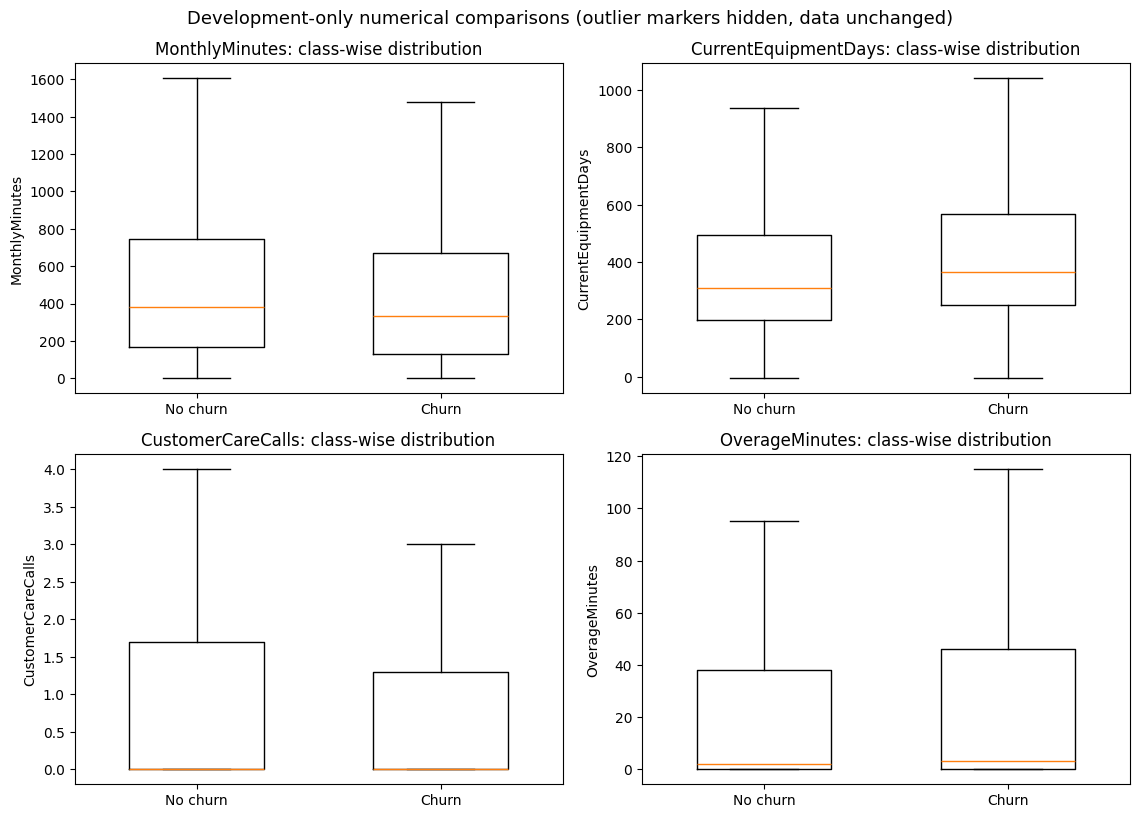

In [ ]:
boxplot_features = ["MonthlyMinutes", "CurrentEquipmentDays", "CustomerCareCalls", "OverageMinutes"]
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.3))
for ax, feature in zip(axes.flat, boxplot_features):
    no_values = X_dev.loc[y_dev == 0, feature].dropna()
    yes_values = X_dev.loc[y_dev == 1, feature].dropna()
    ax.boxplot([no_values, yes_values], showfliers=False, widths=0.55)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["No churn", "Churn"])
    ax.set_ylabel(feature)
    ax.set_title(f"{feature}: class-wise distribution")
fig.suptitle("Development-only numerical comparisons (outlier markers hidden, data unchanged)", fontsize=13)
plt.tight_layout()
plt.show()

**Interpretation.** The median `MonthlyMinutes` is **381** among non-churners versus **331** among churners, while median `CurrentEquipmentDays` is **310** versus **367**, respectively. These are descriptive differences in customer usage and equipment age. In contrast, `CustomerCareCalls` has a median of **zero in both classes**, illustrating why means, full distributions and grouped rates can reveal patterns that a single median misses.

### 4.6 Churn Rates Across Numerical Ranges

Overall means can conceal **nonlinear patterns**. Compare churn rates across meaningful ranges of tenure and customer-care activity, and exploratory **quintile groups** of monthly minutes and equipment age.

- **Fixed descriptive bands** are used for `MonthsInService` and `CustomerCareCalls`.
- **Development-derived quintiles** are used only to visualise `MonthlyMinutes` and `CurrentEquipmentDays`.
- Each bar is annotated with its **sample size**, and each plot has the **same dashed 28.82% development baseline**.

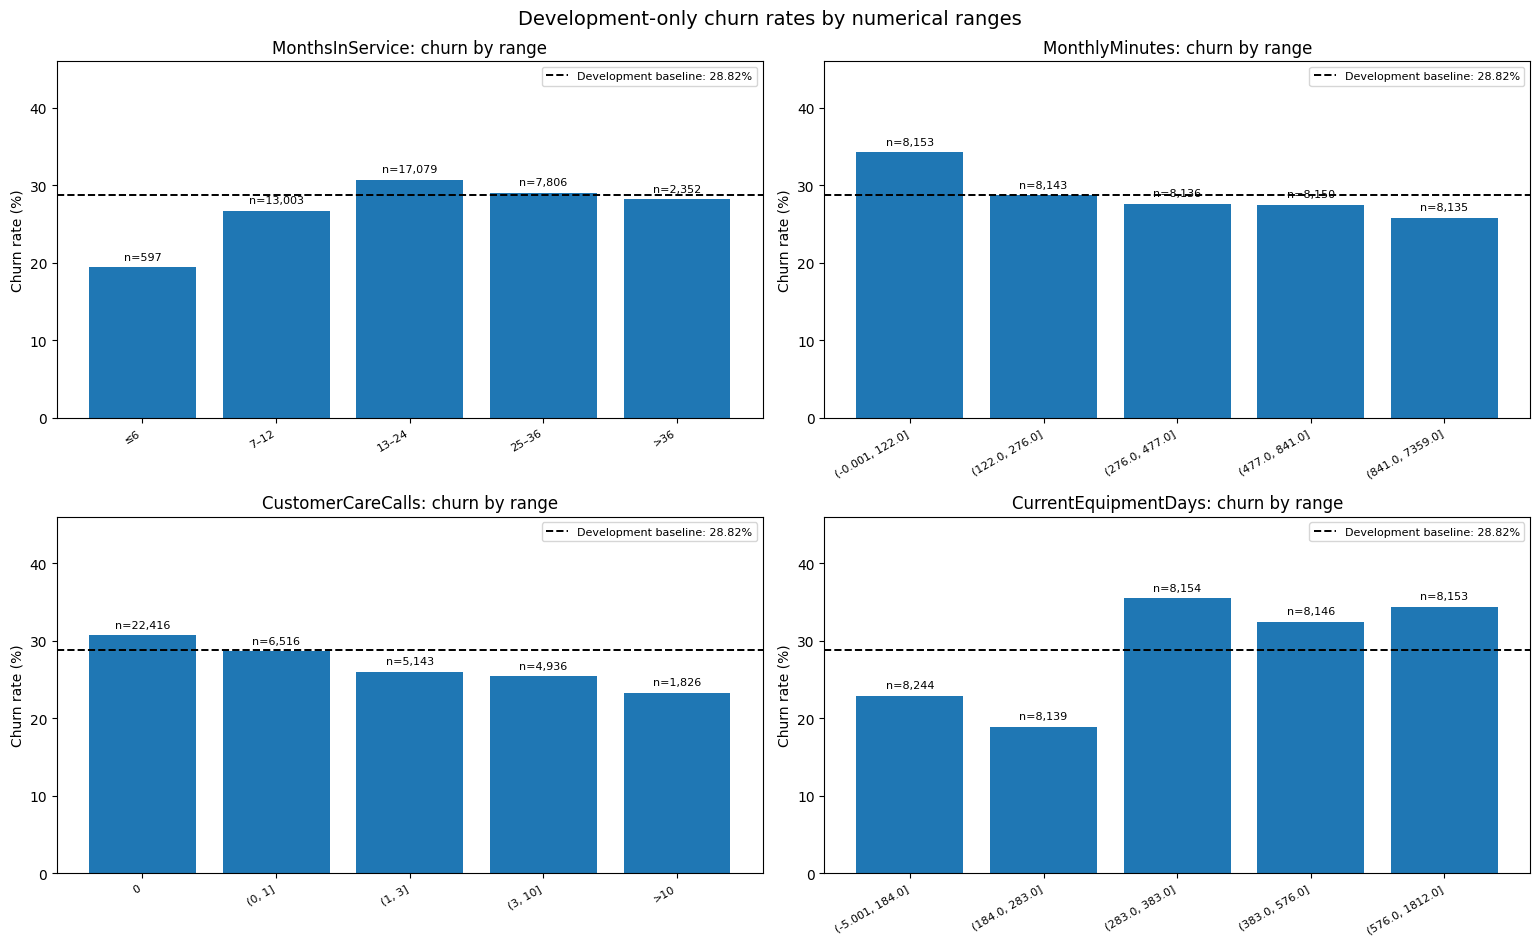

,Feature,Band,N,Churn_N,Churn_rate_pct,Delta_vs_baseline_pp
0,MonthsInService,≤6,597,116,19.43,-9.39
1,MonthsInService,7–12,13003,3475,26.72,-2.09
2,MonthsInService,13–24,17079,5251,30.75,1.93
3,MonthsInService,25–36,7806,2264,29.00,0.18
4,MonthsInService,>36,2352,663,28.19,-0.63
5,MonthlyMinutes,"(-0.001, 122.0]",8153,2795,34.28,5.46
6,MonthlyMinutes,"(122.0, 276.0]",8143,2337,28.70,-0.12
7,MonthlyMinutes,"(276.0, 477.0]",8136,2246,27.61,-1.21
8,MonthlyMinutes,"(477.0, 841.0]",8150,2238,27.46,-1.36
9,MonthlyMinutes,"(841.0, 7359.0]",8135,2098,25.79,-3.03


In [ ]:
num_band_definitions = {
    "MonthsInService": pd.cut(
        X_dev["MonthsInService"],
        bins=[-np.inf, 6, 12, 24, 36, np.inf],
        labels=["≤6", "7–12", "13–24", "25–36", ">36"],
    ),
    "MonthlyMinutes": pd.qcut(X_dev["MonthlyMinutes"], q=5, duplicates="drop"),
    "CustomerCareCalls": pd.cut(
        X_dev["CustomerCareCalls"],
        bins=[-np.inf, 0, 1, 3, 10, np.inf],
        labels=["0", "(0, 1]", "(1, 3]", "(3, 10]", ">10"],
    ),
    "CurrentEquipmentDays": pd.qcut(X_dev["CurrentEquipmentDays"], q=5, duplicates="drop"),
}

numerical_band_summaries = {}
for feature, bands in num_band_definitions.items():
    grouped = (pd.DataFrame({"Band": bands, "Churn": y_dev})
               .dropna(subset=["Band"])
               .groupby("Band", observed=True)["Churn"]
               .agg(N="size", Churn_N="sum", Churn_rate="mean")
               .reset_index())
    grouped["Churn_rate_pct"] = 100 * grouped["Churn_rate"]
    grouped["Delta_vs_baseline_pp"] = grouped["Churn_rate_pct"] - DEV_CHURN_PCT
    numerical_band_summaries[feature] = grouped

fig, axes = plt.subplots(2, 2, figsize=(15.5, 9.6))
for ax, (feature, summary) in zip(axes.flat, numerical_band_summaries.items()):
    xpos = np.arange(len(summary))
    bars = ax.bar(xpos, summary["Churn_rate_pct"])
    add_churn_baseline(ax, "horizontal")
    ax.set_xticks(xpos)
    ax.set_xticklabels(summary["Band"].astype(str), rotation=30, ha="right", fontsize=8)
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(f"{feature}: churn by range")
    ax.set_ylim(0, max(46, float(summary["Churn_rate_pct"].max()) + 9))
    for bar, n in zip(bars, summary["N"]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.7,
                f"n={n:,}", ha="center", va="bottom", fontsize=8)
    ax.legend(loc="upper right", fontsize=8)
fig.suptitle("Development-only churn rates by numerical ranges", fontsize=14)
plt.tight_layout()
plt.show()

numerical_band_table = pd.concat([
    summary.assign(Feature=feature, Band=summary["Band"].astype(str))
    for feature, summary in numerical_band_summaries.items()
], ignore_index=True)
display(numerical_band_table[
    ["Feature", "Band", "N", "Churn_N", "Churn_rate_pct", "Delta_vs_baseline_pp"]
].round(2))

**Interpretation.** The lowest `MonthlyMinutes` quintile has a churn rate of approximately **34.28%**, compared with **25.79%** in the highest quintile; the development baseline is **28.82%**. `CurrentEquipmentDays` shows a **non-monotonic** pattern: the second quintile is approximately **18.91%**, while the third is approximately **35.49%**. `MonthsInService` and `CustomerCareCalls` also vary by range, rather than necessarily following a simple linear trend.

These patterns justify investigating nonlinear relationships during model development. They do **not** justify choosing thresholds or discarding variables from these exploratory charts alone. Subgroup counts are displayed to prevent overinterpreting rates based on small samples.

### 4.7 Categorical Features and Churn Rates

Compare selected customer, equipment and profile categories. Each chart reports **both the churn percentage and the number of customers** in each category. The dashed line is always the **development baseline**, not the average of the displayed categories. It does not encode categories or assume that differences are causal.

`CreditRating` labels contain a meaningful apparent order, whereas `PrizmCode`, `Occupation` and other text categories are not automatically ordered.

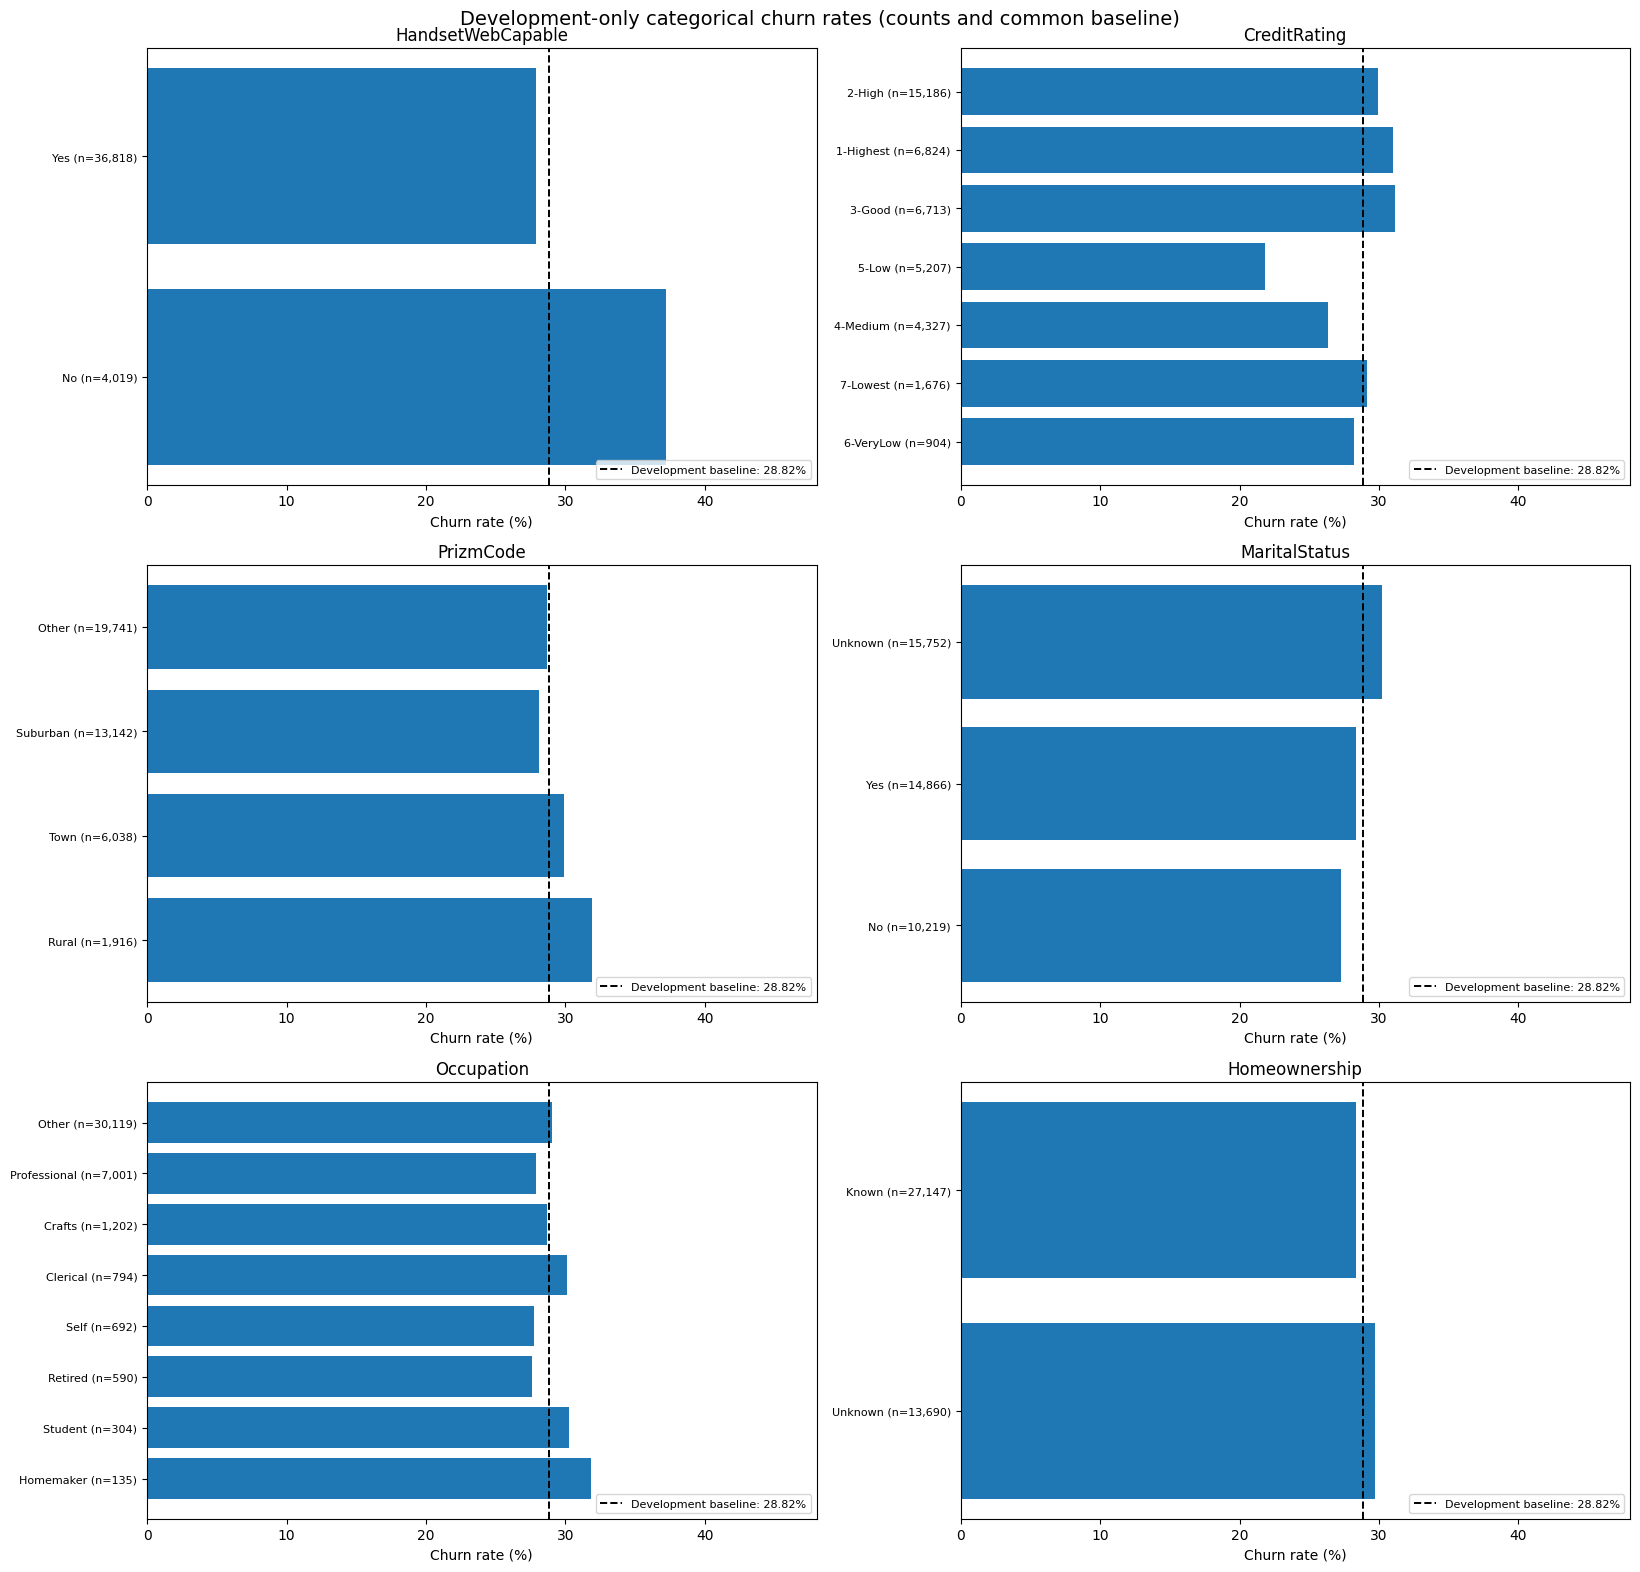

,Feature,Category,N,Churn_N,Churn_rate_pct,Delta_vs_baseline_pp
0,HandsetWebCapable,Yes,36818,10274,27.90,-0.91
1,HandsetWebCapable,No,4019,1495,37.20,8.38
2,CreditRating,2-High,15186,4543,29.92,1.10
3,CreditRating,1-Highest,6824,2117,31.02,2.20
4,CreditRating,3-Good,6713,2090,31.13,2.31
5,CreditRating,5-Low,5207,1135,21.80,-7.02
6,CreditRating,4-Medium,4327,1140,26.35,-2.47
7,CreditRating,7-Lowest,1676,489,29.18,0.36
8,CreditRating,6-VeryLow,904,255,28.21,-0.61
9,PrizmCode,Other,19741,5657,28.66,-0.16


In [ ]:
eda_categorical_features = [
    "HandsetWebCapable", "CreditRating", "PrizmCode",
    "MaritalStatus", "Occupation", "Homeownership",
]
category_summaries = {}
for feature in eda_categorical_features:
    category = X_dev[feature].astype("string").fillna("<Missing>")
    grouped = (pd.DataFrame({"Category": category, "Churn": y_dev})
               .groupby("Category", dropna=False)["Churn"]
               .agg(N="size", Churn_N="sum", Churn_rate="mean")
               .sort_values("N", ascending=False)
               .reset_index())
    grouped["Churn_rate_pct"] = 100 * grouped["Churn_rate"]
    grouped["Delta_vs_baseline_pp"] = grouped["Churn_rate_pct"] - DEV_CHURN_PCT
    category_summaries[feature] = grouped

fig, axes = plt.subplots(3, 2, figsize=(16.5, 16))
for ax, (feature, summary) in zip(axes.flat, category_summaries.items()):
    ypos = np.arange(len(summary))
    ax.barh(ypos, summary["Churn_rate_pct"])
    add_churn_baseline(ax, "vertical")
    ax.set_yticks(ypos)
    ax.set_yticklabels([f"{cat} (n={n:,})" for cat, n in
                        zip(summary["Category"], summary["N"])], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, max(48, float(summary["Churn_rate_pct"].max()) + 6))
    ax.set_xlabel("Churn rate (%)")
    ax.set_title(feature)
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Development-only categorical churn rates (counts and common baseline)", fontsize=14)
plt.tight_layout()
plt.show()

categorical_churn_table = pd.concat([
    summary.assign(Feature=feature) for feature, summary in category_summaries.items()
], ignore_index=True)
display(categorical_churn_table[
    ["Feature", "Category", "N", "Churn_N", "Churn_rate_pct", "Delta_vs_baseline_pp"]
].round(2))

**Interpretation.** Customers with `HandsetWebCapable = No` show approximately **37.20% churn** (4,019 customers), compared with **27.90%** for `Yes` (36,818 customers). `MaritalStatus = Unknown` has approximately **30.21% churn**, modestly above the **28.82% baseline**. `CreditRating` and `Occupation` categories also differ, but **smaller category counts** make some percentages less stable. These associations may reflect other customer characteristics; they are not proof of causal effects or a reason to make final feature-selection decisions during EDA.

### 4.8 Missingness, Explicit `Unknown` Values and Churn

Here check whether customers with a missing or explicitly `Unknown` value have a different observed churn rate from customers without that flag.
Keep **true nulls** and **explicit `Unknown` strings** conceptually distinct, no nulls are filled and no missingness indicators are added to the model inputs yet.

,Flag,Flagged_N,Flagged_%,Flagged_churn_%,Unflagged_churn_%,Delta_vs_baseline_pp
0,PercChangeMinutes: null,290,0.71,56.90,28.62,28.08
1,MonthlyRevenue: null,120,0.29,45.83,28.77,17.01
2,AgeHH1: null,716,1.75,27.79,28.84,-1.03
3,ServiceArea: null,21,0.05,47.62,28.81,18.80
4,HandsetPrice: Unknown,23214,56.85,30.01,27.25,1.19
5,MaritalStatus: Unknown,15752,38.57,30.21,27.94,1.39
6,Homeownership: Unknown,13690,33.52,29.70,28.38,0.88


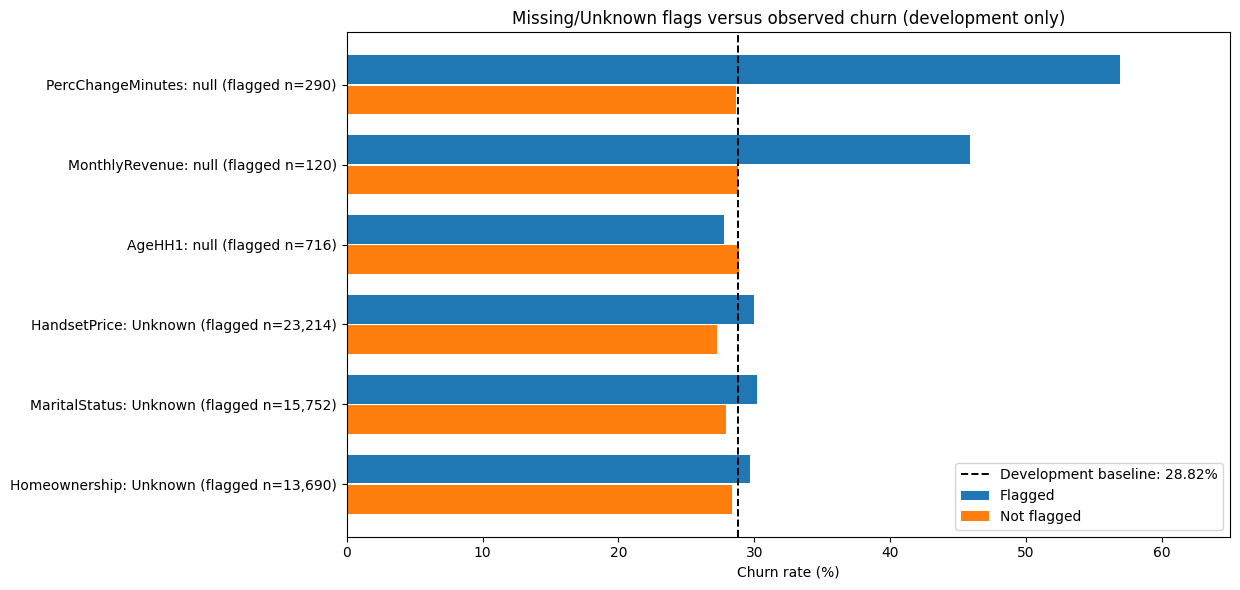

In [ ]:
missingness_flags = {
    "PercChangeMinutes: null": X_dev["PercChangeMinutes"].isna(),
    "MonthlyRevenue: null": X_dev["MonthlyRevenue"].isna(),
    "AgeHH1: null": X_dev["AgeHH1"].isna(),
    "ServiceArea: null": X_dev["ServiceArea"].isna(),
    "HandsetPrice: Unknown": X_dev["HandsetPrice"].astype("string").str.strip().eq("Unknown").fillna(False),
    "MaritalStatus: Unknown": X_dev["MaritalStatus"].astype("string").str.strip().eq("Unknown").fillna(False),
    "Homeownership: Unknown": X_dev["Homeownership"].astype("string").str.strip().eq("Unknown").fillna(False),
}
missingness_rows = []
for label, flag in missingness_flags.items():
    flag = flag.astype(bool)
    n_flagged = int(flag.sum())
    n_unflagged = int((~flag).sum())
    missingness_rows.append({
        "Flag": label,
        "Flagged_N": n_flagged,
        "Flagged_%": 100 * n_flagged / len(flag),
        "Flagged_churn_%": 100 * y_dev[flag].mean() if n_flagged else np.nan,
        "Unflagged_churn_%": 100 * y_dev[~flag].mean() if n_unflagged else np.nan,
        "Delta_vs_baseline_pp": (100 * y_dev[flag].mean() - DEV_CHURN_PCT) if n_flagged else np.nan,
    })
missingness_churn_summary = pd.DataFrame(missingness_rows)
display(missingness_churn_summary.round(2))

# Exclude the very small flagged groups from the comparison plot, but keep them in the table.
plot_missing = missingness_churn_summary.query("Flagged_N >= 100").copy()
ypos = np.arange(len(plot_missing))
fig, ax = plt.subplots(figsize=(12.5, 6))
ax.barh(ypos - 0.19, plot_missing["Flagged_churn_%"], height=0.36, label="Flagged")
ax.barh(ypos + 0.19, plot_missing["Unflagged_churn_%"], height=0.36, label="Not flagged")
add_churn_baseline(ax, "vertical")
ax.set_yticks(ypos)
ax.set_yticklabels([f"{label} (flagged n={n:,})" for label, n in
                    zip(plot_missing["Flag"], plot_missing["Flagged_N"])])
ax.invert_yaxis()
ax.set_xlabel("Churn rate (%)")
ax.set_xlim(0, max(65, float(plot_missing["Flagged_churn_%"].max()) + 5))
ax.set_title("Missing/Unknown flags versus observed churn (development only)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation.** In the development set, customers missing `PercChangeMinutes` have approximately **56.90% churn** (**290** customers), compared with approximately **28.62%** among those with recorded values. Missing `MonthlyRevenue` is also associated with higher observed churn (**45.83%**, **120** customers). `HandsetPrice = Unknown` has approximately **30.01% churn**, versus **27.25%** when a value is recorded.

### 4.9 Relationships and Potential Redundancy Among Numerical Predictors

Examine **Pearson correlations between numerical predictors** on the development partition. A strong positive or negative correlation indicates a *linear association* between two observed features; it does not establish that either feature causes churn or that one should automatically be dropped. Pairwise missing values are handled by pandas' default pairwise-complete correlation calculation.

To keep the figure readable, the heatmap displays a selected group of usage, billing and account variables; the accompanying ranked table searches **all numerically stored predictors** for highly correlated pairs.

,Feature_1,Feature_2,Pearson_r,Absolute_r
516,Handsets,HandsetModels,0.888,0.888
44,MonthlyMinutes,ReceivedCalls,0.827,0.827
269,BlockedCalls,DroppedBlockedCalls,0.816,0.816
495,UniqueSubs,ActiveSubs,0.805,0.805
3,MonthlyRevenue,OverageMinutes,0.783,0.783
47,MonthlyMinutes,PeakCallsInOut,0.773,0.773
48,MonthlyMinutes,OffPeakCallsInOut,0.765,0.765
353,ReceivedCalls,PeakCallsInOut,0.746,0.746
373,OutboundCalls,OffPeakCallsInOut,0.740,0.740
354,ReceivedCalls,OffPeakCallsInOut,0.736,0.736


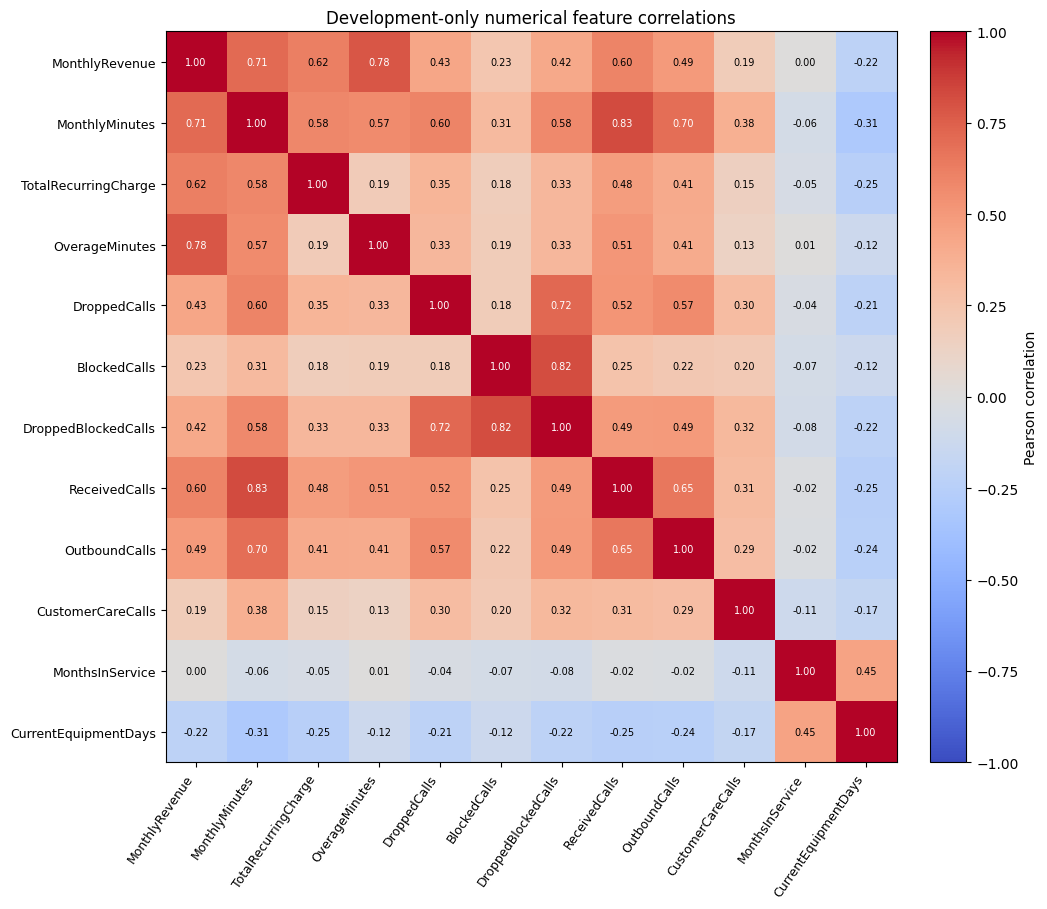

In [ ]:
eda_numeric_corr = X_dev[eda_numeric_columns].corr(method="pearson")
upper_triangle = np.triu(np.ones(eda_numeric_corr.shape, dtype=bool), k=1)
correlation_pairs = (eda_numeric_corr.where(upper_triangle)
                     .stack()
                     .rename("Pearson_r")
                     .reset_index())
correlation_pairs.columns = ["Feature_1", "Feature_2", "Pearson_r"]
correlation_pairs["Absolute_r"] = correlation_pairs["Pearson_r"].abs()
correlation_pairs = correlation_pairs.sort_values("Absolute_r", ascending=False)
display(correlation_pairs.head(12).round(3))

heatmap_features = [
    "MonthlyRevenue", "MonthlyMinutes", "TotalRecurringCharge", "OverageMinutes",
    "DroppedCalls", "BlockedCalls", "DroppedBlockedCalls", "ReceivedCalls",
    "OutboundCalls", "CustomerCareCalls", "MonthsInService", "CurrentEquipmentDays",
]
heat = eda_numeric_corr.loc[heatmap_features, heatmap_features]
fig, ax = plt.subplots(figsize=(10.5, 9.2))
im = ax.imshow(heat.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(heatmap_features)))
ax.set_xticklabels(heatmap_features, rotation=55, ha="right", fontsize=9)
ax.set_yticks(range(len(heatmap_features)))
ax.set_yticklabels(heatmap_features, fontsize=9)
for row in range(len(heatmap_features)):
    for col in range(len(heatmap_features)):
        val = heat.iat[row, col]
        if np.isfinite(val):
            ax.text(col, row, f"{val:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(val) > 0.65 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
ax.set_title("Development-only numerical feature correlations")
plt.tight_layout()
plt.show()

**Interpretation.** Several usage and account measures are strongly correlated. For example, `Handsets` and `HandsetModels` have a Pearson correlation of approximately **0.89**, while `MonthlyMinutes` and `ReceivedCalls` are approximately **0.83**. This suggests possible overlapping information, but correlated predictors can still be useful, especially for different algorithms.

### 4.10 High-Cardinality `ServiceArea`: Coverage and Churn Stability

`ServiceArea` has many distinct codes. Examine how often those codes appear in the **development** data and display churn rates for the **ten most frequent** areas. Selecting by **frequency rather than observed churn rate** avoids showcasing only extreme, potentially unstable outcomes. Rare categories and categories unseen in a validation fold will require careful handling by the future categorical preprocessing pipeline.

,Measure,Value
0,Distinct nonmissing ServiceArea codes,729
1,Customers with missing ServiceArea,21
2,Codes with fewer than 20 development customers,434
3,Customers in codes with fewer than 20 records,2441
4,Codes with fewer than 50 development customers,546


,ServiceArea,N,Churn_N,Churn_rate_pct,Delta_vs_baseline_pp
0,NYCBRO917,1330,360,27.07,-1.75
1,HOUHOU281,1232,310,25.16,-3.66
2,DALDAL214,1195,340,28.45,-0.37
3,NYCMAN917,956,268,28.03,-0.79
4,DALFTW817,636,174,27.36,-1.46
5,APCFCH703,625,176,28.16,-0.66
6,SANSAN210,575,161,28.00,-0.82
7,APCSIL301,526,133,25.29,-3.53
8,SFROAK510,510,152,29.80,0.98
9,SANAUS512,497,135,27.16,-1.66


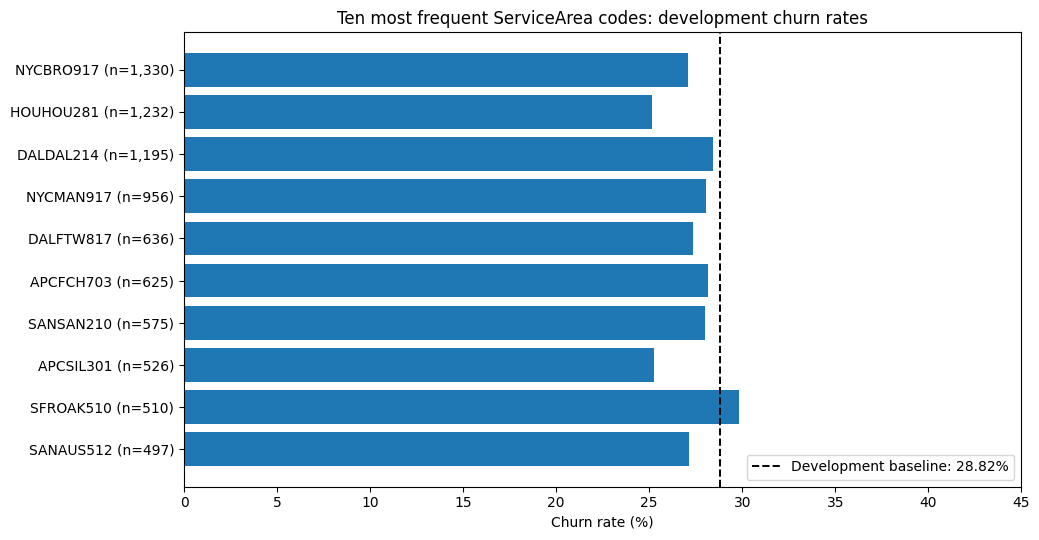

In [ ]:
service_area = X_dev["ServiceArea"].astype("string").fillna("<Missing>")
service_counts = service_area.value_counts()
service_summary = pd.DataFrame([
    {"Measure": "Distinct nonmissing ServiceArea codes", "Value": X_dev["ServiceArea"].nunique(dropna=True)},
    {"Measure": "Customers with missing ServiceArea", "Value": int(X_dev["ServiceArea"].isna().sum())},
    {"Measure": "Codes with fewer than 20 development customers", "Value": int((service_counts < 20).sum())},
    {"Measure": "Customers in codes with fewer than 20 records", "Value": int(service_counts[service_counts < 20].sum())},
    {"Measure": "Codes with fewer than 50 development customers", "Value": int((service_counts < 50).sum())},
])
display(service_summary)

service_churn = (pd.DataFrame({"ServiceArea": service_area, "Churn": y_dev})
                 .groupby("ServiceArea")["Churn"]
                 .agg(N="size", Churn_N="sum", Churn_rate="mean"))
top_areas = service_counts.head(10).index
service_top10 = service_churn.loc[top_areas].reset_index()
service_top10["Churn_rate_pct"] = 100 * service_top10["Churn_rate"]
service_top10["Delta_vs_baseline_pp"] = service_top10["Churn_rate_pct"] - DEV_CHURN_PCT
display(service_top10[["ServiceArea", "N", "Churn_N", "Churn_rate_pct", "Delta_vs_baseline_pp"]].round(2))

fig, ax = plt.subplots(figsize=(10.5, 5.5))
ypos = np.arange(len(service_top10))
ax.barh(ypos, service_top10["Churn_rate_pct"])
add_churn_baseline(ax, "vertical")
ax.set_yticks(ypos)
ax.set_yticklabels([f"{name} (n={n:,})" for name, n in
                    zip(service_top10["ServiceArea"], service_top10["N"])])
ax.invert_yaxis()
ax.set_xlabel("Churn rate (%)")
ax.set_xlim(0, max(45, float(service_top10["Churn_rate_pct"].max()) + 6))
ax.set_title("Ten most frequent ServiceArea codes: development churn rates")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation.** The development partition contains **729 distinct nonmissing `ServiceArea` codes**, with **21 missing values**. **434 codes have fewer than 20 development customers** (2,441 customers across those codes). This is a strong reason to investigate rare-category and unseen-category handling when designing the categorical encoder. The displayed ten areas were selected by **sample size**, and their observed churn rates should be interpreted relative to the **28.82% baseline**.

### 4.11 Prediction-Time Feature Availability and Retention Leakage Risk

**Important distinction:** A variable may be highly associated with churn and still be **unusable for prediction** if its value becomes known only after the chosen scoring time. A retention intervention may also occur *because* the customer has already signalled an intention to leave. The supplied Cell2Cell files do **not** establish when these events were recorded relative to the churn outcome.

For each potentially time-sensitive variable, we need evidence of (1) its precise definition, (2) when it was measured, (3) whether it was available at scoring time and (4) whether it includes information from after a cancellation or retention intervention. Without that evidence, an observed association is **not proof of leakage**, but neither is it proof of legitimate availability.

**Conservative pre-modelling policy:** unless reliable dataset documentation verifies pre-outcome availability, plan to **exclude `RetentionCalls`, `RetentionOffersAccepted` and `MadeCallToRetentionTeam` from the primary deployment-oriented model**. A separate *development-only* sensitivity comparison with those fields may be reported as an exploratory diagnostic, but must not be used to choose a feature set using the final test. This policy is documented here; **no columns are removed from `X_dev` in Section 4**. The final feature policy will be locked before modelling.

In [ ]:
RETENTION_FEATURES_UNVERIFIED = [
    "RetentionCalls", "RetentionOffersAccepted", "MadeCallToRetentionTeam"
]
assert set(RETENTION_FEATURES_UNVERIFIED).issubset(X_dev.columns)

feature_timing_review = pd.DataFrame([
    {
        "Feature": "RetentionCalls",
        "What_it_records": "Number of retention-related calls",
        "What_must_be_verified": "Call dates relative to scoring and churn outcome",
        "Evidence_in_files": "No event dates / cutoff definition",
        "Status": "Timing unverified",
        "Provisional_primary_policy": "Exclude unless pre-outcome availability is verified",
    },
    {
        "Feature": "RetentionOffersAccepted",
        "What_it_records": "Accepted retention offers",
        "What_must_be_verified": "Offer and acceptance dates; whether offer follows churn intent",
        "Evidence_in_files": "No event dates / cutoff definition",
        "Status": "Timing unverified",
        "Provisional_primary_policy": "Exclude unless pre-outcome availability is verified",
    },
    {
        "Feature": "MadeCallToRetentionTeam",
        "What_it_records": "Whether the customer contacted the retention team",
        "What_must_be_verified": "Contact timing and triggering event",
        "Evidence_in_files": "No event dates / cutoff definition",
        "Status": "Timing unverified",
        "Provisional_primary_policy": "Exclude unless pre-outcome availability is verified",
    },
    {
        "Feature": "PercChangeMinutes / PercChangeRevenues",
        "What_it_records": "Change in usage / revenue over an unspecified interval",
        "What_must_be_verified": "Observation window and whether it precedes churn",
        "Evidence_in_files": "No dated observation window",
        "Status": "Timing unverified",
        "Provisional_primary_policy": "Review observation window before modelling",
    },
])
display(feature_timing_review)

,Feature,What_it_records,What_must_be_verified,Evidence_in_files,Status,Provisional_primary_policy
0,RetentionCalls,Number of retention-related calls,Call dates relative to scoring and churn outcome,No event dates / cutoff definition,Timing unverified,Exclude unless pre-outcome availability is ver...
1,RetentionOffersAccepted,Accepted retention offers,Offer and acceptance dates; whether offer foll...,No event dates / cutoff definition,Timing unverified,Exclude unless pre-outcome availability is ver...
2,MadeCallToRetentionTeam,Whether the customer contacted the retention team,Contact timing and triggering event,No event dates / cutoff definition,Timing unverified,Exclude unless pre-outcome availability is ver...
3,PercChangeMinutes / PercChangeRevenues,Change in usage / revenue over an unspecified ...,Observation window and whether it precedes churn,No dated observation window,Timing unverified,Review observation window before modelling


,Observed_indicator,Flagged_N,Flagged_%,Flagged_churn_%,Not_flagged_churn_%,Delta_vs_baseline_pp
0,RetentionCalls > 0,1402,3.43,44.86,28.25,16.05
1,RetentionOffersAccepted > 0,711,1.74,42.33,28.58,13.52
2,MadeCallToRetentionTeam = Yes,1402,3.43,44.86,28.25,16.05


RetentionCalls > 0 exactly matches MadeCallToRetentionTeam = Yes in development: True


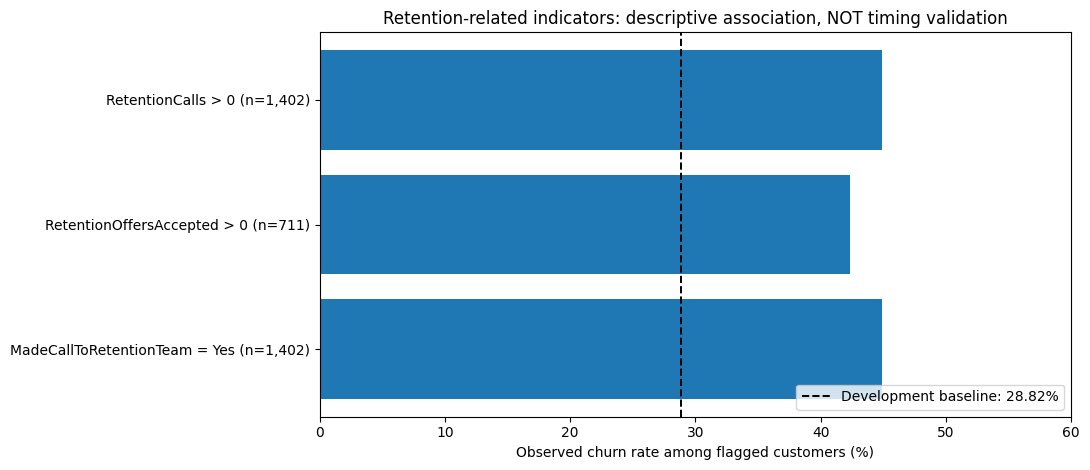

In [ ]:
retention_flags = {
    "RetentionCalls > 0": X_dev["RetentionCalls"].gt(0),
    "RetentionOffersAccepted > 0": X_dev["RetentionOffersAccepted"].gt(0),
    "MadeCallToRetentionTeam = Yes": X_dev["MadeCallToRetentionTeam"].eq("Yes"),
}
retention_rows = []
for label, flag in retention_flags.items():
    n_flagged = int(flag.sum())
    retention_rows.append({
        "Observed_indicator": label,
        "Flagged_N": n_flagged,
        "Flagged_%": 100 * flag.mean(),
        "Flagged_churn_%": 100 * y_dev[flag].mean(),
        "Not_flagged_churn_%": 100 * y_dev[~flag].mean(),
        "Delta_vs_baseline_pp": 100 * y_dev[flag].mean() - DEV_CHURN_PCT,
    })
retention_churn_summary = pd.DataFrame(retention_rows)
display(retention_churn_summary.round(2))

# This is an observed relationship, not an assumed business rule.
retention_call_indicator_matches = bool(
    X_dev["RetentionCalls"].gt(0).equals(X_dev["MadeCallToRetentionTeam"].eq("Yes"))
)
print("RetentionCalls > 0 exactly matches MadeCallToRetentionTeam = Yes in development:",
      retention_call_indicator_matches)

fig, ax = plt.subplots(figsize=(11, 4.8))
ypos = np.arange(len(retention_churn_summary))
ax.barh(ypos, retention_churn_summary["Flagged_churn_%"])
add_churn_baseline(ax, "vertical")
ax.set_yticks(ypos)
ax.set_yticklabels([f"{label} (n={n:,})" for label, n in
                    zip(retention_churn_summary["Observed_indicator"],
                        retention_churn_summary["Flagged_N"])])
ax.invert_yaxis()
ax.set_xlim(0, max(60, float(retention_churn_summary["Flagged_churn_%"].max()) + 6))
ax.set_xlabel("Observed churn rate among flagged customers (%)")
ax.set_title("Retention-related indicators: descriptive association, NOT timing validation")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation.** In development data, customers with `RetentionCalls > 0` show approximately **44.86% churn** (**1,402 customers**), versus **28.25%** for those without retention calls. `MadeCallToRetentionTeam = Yes` identifies **exactly the same 1,402 customers** in this partition, indicating a redundant binary indicator. Customers with `RetentionOffersAccepted > 0` show approximately **42.33% churn** (**711 customers**). All are above the **28.82% development baseline**.

**Crucially, these percentages do not tell us *when* the information became available.** They are not evidence that the features are safe to use for pre-churn prediction, nor proof that they are definitely leaky. The conservative primary-feature exclusion remains **provisional pending timing documentation**, and no model input has been altered here. The missing prediction timestamps and undefined forecast horizon limit the strength of any real-world deployment claim.

### 4.12 EDA Findings, Limitations and Implications for the Next Stage

The following evidence table connects the **observed development-only results** to later preprocessing and modelling work. These are **candidate hypotheses and data-handling considerations**, not confirmed causal explanations, selected model features or final test results.

In [ ]:
# Concise evidence register based only on development data and computed summaries.
eda_findings = pd.DataFrame([
    {
        "Observation": "Development churn prevalence",
        "Evidence": f"{DEV_CHURN_PCT:.2f}% churn ({int(y_dev.sum()):,}/{len(y_dev):,})",
        "Implication": "Use this baseline on subgroup plots; evaluate beyond accuracy",
    },
    {
        "Observation": "Numerical skew and excess zeros",
        "Evidence": (f"RoamingCalls zero for {100*X_dev['RoamingCalls'].eq(0).mean():.1f}%; "
                     f"CustomerCareCalls zero for {100*X_dev['CustomerCareCalls'].eq(0).mean():.1f}%"),
        "Implication": "Review scaling and robust representations within training folds",
    },
    {
        "Observation": "Usage differs by churn outcome",
        "Evidence": (f"Median MonthlyMinutes: No={X_dev.loc[y_dev==0,'MonthlyMinutes'].median():.0f}; "
                     f"Yes={X_dev.loc[y_dev==1,'MonthlyMinutes'].median():.0f}"),
        "Implication": "Investigate usage patterns with leakage-safe model comparisons",
    },
    {
        "Observation": "Equipment age differs by churn outcome",
        "Evidence": (f"Median CurrentEquipmentDays: No={X_dev.loc[y_dev==0,'CurrentEquipmentDays'].median():.0f}; "
                     f"Yes={X_dev.loc[y_dev==1,'CurrentEquipmentDays'].median():.0f}"),
        "Implication": "Consider nonlinear relationships; do not infer causation",
    },
    {
        "Observation": "Some missingness is associated with churn",
        "Evidence": (f"PercChangeMinutes null: "
                     f"{100*y_dev[X_dev['PercChangeMinutes'].isna()].mean():.2f}% churn "
                     f"(n={int(X_dev['PercChangeMinutes'].isna().sum())})"),
        "Implication": "Evaluate imputation and optional missingness indicators within CV",
    },
    {
        "Observation": "High-cardinality service codes",
        "Evidence": (f"{X_dev['ServiceArea'].nunique()} nonmissing ServiceArea codes; "
                     f"{int((service_counts < 20).sum())} categories have <20 rows"),
        "Implication": "Plan rare/unseen-category handling for the categorical encoder",
    },
    {
        "Observation": "Retention timing cannot be verified",
        "Evidence": "Retention indicators associated with churn; no event timestamps",
        "Implication": "Conservative primary exclusion pending verification; development-only sensitivity study",
    },
])
display(eda_findings)
print("Section 4 complete: development-only EDA; no fitted preprocessing or model training.")

,Observation,Evidence,Implication
0,Development churn prevalence,"28.82% churn (11,769/40,837)",Use this baseline on subgroup plots; evaluate ...
1,Numerical skew and excess zeros,RoamingCalls zero for 68.7%; CustomerCareCalls...,Review scaling and robust representations with...
2,Usage differs by churn outcome,Median MonthlyMinutes: No=381; Yes=331,Investigate usage patterns with leakage-safe m...
3,Equipment age differs by churn outcome,Median CurrentEquipmentDays: No=310; Yes=367,Consider nonlinear relationships; do not infer...
4,Some missingness is associated with churn,PercChangeMinutes null: 56.90% churn (n=290),Evaluate imputation and optional missingness i...
5,High-cardinality service codes,729 nonmissing ServiceArea codes; 434 categori...,Plan rare/unseen-category handling for the cat...
6,Retention timing cannot be verified,Retention indicators associated with churn; no...,Conservative primary exclusion pending verific...


Section 4 complete: development-only EDA; no fitted preprocessing or model training.


**Overall interpretation and transition.** EDA shows that numerical distributions are often skewed and zero-heavy; subgroup churn rates differ from the **28.82% development baseline**; missingness and some categorical values are associated with churn; and several numerical predictors are correlated. These observations are **descriptive** and may reflect confounding, sampling variability or dataset-specific coding conventions. We have **not** established causal relationships, a future forecasting horizon or the temporal validity of retention variables.

**Safeguards for subsequent sections:**

1. **Section 5 — Data Preparation and Preprocessing:** choose and implement suitable numerical/categorical handling using `Pipeline` and `ColumnTransformer`. Any learned imputation values, encoding categories, scaling parameters or rare-category thresholds must be fitted on the **training fold only** during cross-validation.
2. **Section 6 — Feature Analysis and Prediction-Time Policy:** verify feature meaning/availability where possible; establish a conservative primary feature set **before modelling**. Exploratory relationships in this section must not be treated as independently validated feature-selection results.
3. **Later model development:** compare Logistic Regression and Random Forest under the **same development-only validation protocol**, using Average Precision as the predefined primary metric and appropriate supporting metrics. Reserve the **protected final test** for one evaluation after choices are fixed.

`X_dev`, `y_dev`, `X_test`, `y_test`, `train_raw` and `holdout_raw` have not been overwritten by the EDA.

5 — Data Preprocessing


5.1 Import preprocessing tools

In [ ]:
# Section 5: Data Preprocessing

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Preprocessing libraries imported successfully.")

Preprocessing libraries imported successfully.


5.2 Create working copies and clean data types

This ensures that the original raw dataset remains untouched. It also changes HandsetPrice to numeric as the notebook review revealed that the column had both price-like values and "Unknown."

In [ ]:
# Create working copies
train_clean = train_raw.copy()
holdout_clean = holdout_raw.copy()

# Remove unnecessary spaces from column names
train_clean.columns = train_clean.columns.str.strip()
holdout_clean.columns = holdout_clean.columns.str.strip()

# Convert handset price to numeric
# Values such as "Unknown" become NaN and will be imputed later.
for df in [train_clean, holdout_clean]:
    df["HandsetPrice"] = pd.to_numeric(
        df["HandsetPrice"],
        errors="coerce"
    )

# Standardise whitespace in categorical text values.
# Preserve explicit "Unknown" values as a category.
for df in [train_clean, holdout_clean]:
    categorical_cols = df.select_dtypes(
        include=["object", "category"]
    ).columns

    for col in categorical_cols:
        df[col] = df[col].apply(
            lambda value: value.strip()
            if isinstance(value, str)
            else value
        )

print("Training data shape:", train_clean.shape)
print("Holdout data shape:", holdout_clean.shape)
print("Data-type cleaning completed.")


Training data shape: (51047, 58)
Holdout data shape: (20000, 58)
Data-type cleaning completed.


5.3 Check missing values after cleaning

The missing data will be imputed using preprocessing pipelines that have been built exclusively using the training dataset without the help of any validation data.

In [ ]:

# Review missing values after type correction

missing_train = (
    train_clean.isnull().sum()
    .sort_values(ascending=False)
)

missing_holdout = (
    holdout_clean.isnull().sum()
    .sort_values(ascending=False)
)

print("Training dataset missing values:")
display(missing_train[missing_train > 0].to_frame("Missing_Count"))

print("Holdout dataset missing values:")
display(missing_holdout[missing_holdout > 0].to_frame("Missing_Count"))


Training dataset missing values:


,Missing_Count
HandsetPrice,28982
AgeHH2,909
AgeHH1,909
PercChangeRevenues,367
PercChangeMinutes,367
DirectorAssistedCalls,156
RoamingCalls,156
TotalRecurringCharge,156
MonthlyRevenue,156
MonthlyMinutes,156


Holdout dataset missing values:


,Missing_Count
Churn,20000
HandsetPrice,11267
AgeHH2,335
AgeHH1,335
PercChangeRevenues,135
PercChangeMinutes,135
RoamingCalls,60
DirectorAssistedCalls,60
MonthlyRevenue,60
MonthlyMinutes,60


5.4 Create meaningful new features

In [ ]:

#Feature Engineering

def engineer_features(df):
    df = df.copy()

    # 1. Convert customer tenure from months to years
    df["TenureYears"] = df["MonthsInService"] / 12

    # 2. Convert equipment age from days to years
    df["EquipmentAgeYears"] = (
        df["CurrentEquipmentDays"] / 365.25
    )

    # 3. Calculate revenue per call minute
    # A zero-minute record produces a missing ratio.
    df["RevenuePerMinute"] = (
        df["MonthlyRevenue"]
        / df["MonthlyMinutes"].replace(0, np.nan)
    )

    return df


# Apply the same feature engineering to both datasets
train_fe = engineer_features(train_clean)
holdout_fe = engineer_features(holdout_clean)

new_features = [
    "TenureYears",
    "EquipmentAgeYears",
    "RevenuePerMinute"
]

print("New features created:")
display(train_fe[new_features].head())

print("Training shape after feature engineering:", train_fe.shape)
print("Holdout shape after feature engineering:", holdout_fe.shape)


New features created:


,TenureYears,EquipmentAgeYears,RevenuePerMinute
0,5.083333,0.988364,0.109589
1,4.833333,4.117728,1.699000
2,5.000000,4.960986,4.750000
3,4.916667,1.253936,0.062713
4,4.416667,2.332649,NaN


Training shape after feature engineering: (51047, 61)
Holdout shape after feature engineering: (20000, 61)


5.5 Separate the target and split the labelled dataset

In [ ]:

# Separate target from predictors

# Exclude rows without a known target, if any exist.
labelled_data = train_fe.dropna(subset=["Churn"]).copy()

X = labelled_data.drop(
    columns=["Churn", "CustomerID"]
)

y = labelled_data["Churn"].astype(str).str.strip()

# Stratified split preserves the approximate class distribution.
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Prepare the unlabelled holdout predictors
X_holdout = holdout_fe.drop(
    columns=["Churn", "CustomerID"]
)

print("Training predictors:", X_train.shape)
print("Validation predictors:", X_valid.shape)
print("Holdout predictors:", X_holdout.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

Training predictors: (40837, 59)
Validation predictors: (10210, 59)
Holdout predictors: (20000, 59)

Training target distribution:


,proportion
Churn,
No,71.18
Yes,28.82


5.6 Identify numerical and categorical columns

In [ ]:

# Identify feature types using the training partition only

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

# Verify that holdout predictors have the same columns
assert X_train.columns.tolist() == X_holdout.columns.tolist()
assert X_train.columns.tolist() == X_valid.columns.tolist()

print("\nFeature columns are consistent across all partitions.")

Number of numerical features: 38
Number of categorical features: 21

Numerical features:
['MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'RetentionCalls', 'RetentionOffersAccepted', 'ReferralsMadeBySubscriber', 'IncomeGroup', 'AdjustmentsToCreditRating', 'HandsetPrice', 'TenureYears', 'EquipmentAgeYears', 'RevenuePerMinute']

Categorical features:
['ServiceArea', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMai

5.7 Impute, encode and scale the features

This is the primary data preprocessing pipeline. Numeric values that are missing are imputed with the median value in training, categorical missing values with the most frequent category in training, categorical variables one-hot-encoded, and numeric variables standardized.

In [ ]:

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and holdout data without refitting
X_valid_processed = preprocessor.transform(X_valid)
X_holdout_processed = preprocessor.transform(X_holdout)

print("Training matrix:", X_train_processed.shape)
print("Validation matrix:", X_valid_processed.shape)
print("Holdout matrix:", X_holdout_processed.shape)

print("\nPreprocessing completed successfully.")

Training matrix: (40837, 821)
Validation matrix: (10210, 821)
Holdout matrix: (20000, 821)

Preprocessing completed successfully.


5.8 Final preprocessing checks

In [ ]:

# Final checks before model training

from scipy import sparse

def check_processed_data(name, data):
    if sparse.issparse(data):
        has_missing = np.isnan(data.data).any()
    else:
        has_missing = np.isnan(data).any()

    print(f"{name}:")
    print("  Shape:", data.shape)
    print("  Contains missing values:", has_missing)


check_processed_data("Training data", X_train_processed)
check_processed_data("Validation data", X_valid_processed)
check_processed_data("Holdout data", X_holdout_processed)

print("\nTarget classes:", sorted(y_train.unique()))
print("Training rows:", X_train_processed.shape[0])
print("Validation rows:", X_valid_processed.shape[0])
print("Holdout rows:", X_holdout_processed.shape[0])

# Confirm that the processed training data has no missing values
if sparse.issparse(X_train_processed):
    assert not np.isnan(X_train_processed.data).any()
else:
    assert not np.isnan(X_train_processed).any()

print("\nAll preprocessing checks completed.")


Training data:
  Shape: (40837, 821)
  Contains missing values: False
Validation data:
  Shape: (10210, 821)
  Contains missing values: False
Holdout data:
  Shape: (20000, 821)
  Contains missing values: False

Target classes: ['No', 'Yes']
Training rows: 40837
Validation rows: 10210
Holdout rows: 20000

All preprocessing checks completed.
